# Off Market Models

In [4]:
import os
import sys

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import ParameterGrid
from xgboost import XGBRegressor

import data
from features import square_feet

scores = []

def percentage_scores(predicted, sold):
    signed = 100 * (np.asarray(predicted) - np.asarray(sold)) / np.asarray(sold)
    absolute = np.abs(signed)
    return {
        "MdAPE": round(float(np.median(absolute)), 2),
        "MAPE": round(float(np.mean(absolute)), 2),
        "median_signed_error": round(float(np.median(signed)), 2),
    }


def add_score(name, predicted, sold):
    row = {"model": name, **percentage_scores(predicted, sold)}
    scores.append(row)
    print(
        f"{name}: MdAPE {row['MdAPE']:.2f}%, "
        f"MAPE {row['MAPE']:.2f}%, "
        f"median signed error {row['median_signed_error']:+.2f}%"
    )

    return row

### Data Split

In [5]:
listings = data.load("listings").copy()
listings["square_feet"] = square_feet(listings["house_area"])

holdout_start = pd.Timestamp("2025-12-01")
train = listings[listings["date_sold"] < holdout_start].copy()
valid = listings[listings["date_sold"] >= holdout_start].copy()
print(f"Train: {len(train):,} sales, {train['date_sold'].min():%Y-%m-%d} to {train['date_sold'].max():%Y-%m-%d}")
print(f"Validation: {len(valid):,} sales, {valid['date_sold'].min():%Y-%m-%d} to {valid['date_sold'].max():%Y-%m-%d}")

Train: 139,931 sales, 2021-01-01 to 2025-11-30
Validation: 10,069 sales, 2025-12-01 to 2026-05-31


## Numerical features

In [6]:
def numeric_design(frame):
    missing_lot = frame["lot_front"].isna()
    X = pd.DataFrame(index=frame.index)
    X["log_square_feet"] = np.log(frame["square_feet"])
    X["lot_missing"] = missing_lot.astype(float)
    X["log_lot_front"] = np.log(frame["lot_front"].where(~missing_lot, 1.0))
    X["lot_depth"] = frame["lot_depth"].fillna(0.0)
    for column in ["bedrooms", "washrooms", "parking_total", "garage", "latitude", "longitude"]:
        X[column] = frame[column].astype(float)
    return X

train_X = sm.add_constant(numeric_design(train),has_constant="add")
valid_X = sm.add_constant(numeric_design(valid), has_constant="add")
train_X.head()

,const,log_square_feet,lot_missing,log_lot_front,lot_depth,bedrooms,washrooms,parking_total,garage,latitude,longitude
0,1.0,6.432940,1.0,0.0,0.0,1.0,1.0,0.0,0.0,43.602039,-79.261184
1,1.0,6.475433,1.0,0.0,0.0,2.0,1.0,0.0,0.0,43.695388,-79.510865
2,1.0,6.907255,1.0,0.0,0.0,2.0,1.0,1.0,0.0,43.740512,-79.386216
3,1.0,6.775366,1.0,0.0,0.0,1.0,1.0,1.0,0.0,43.643774,-79.470180
4,1.0,6.242223,1.0,0.0,0.0,1.0,1.0,1.0,0.0,43.696172,-79.274137


## OLS

In [7]:
raw_columns = [
    "square_feet", "lot_front", "lot_depth",
    "bedrooms", "washrooms", "parking_total","garage", "latitude", "longitude"
]

def raw_design(frame):
    X = frame[raw_columns].copy()
    X["lot_front"] = X["lot_front"].fillna(0.0)
    X["lot_depth"] = X["lot_depth"].fillna(0.0)
    return sm.add_constant(X, has_constant="add")


raw_model = sm.OLS(train["sold_price"], raw_design(train)).fit()
raw_hat = raw_model.predict(raw_design(valid))

add_score("OLS, regular", raw_hat, valid["sold_price"])

OLS, regular: MdAPE 21.76%, MAPE 29.54%, median signed error +14.16%


{'model': 'OLS, regular',
 'MdAPE': 21.76,
 'MAPE': 29.54,
 'median_signed_error': 14.16}

## Log OLS

In [8]:
log_target = pd.Series(np.log(train["sold_price"]), index=train.index, name="log_sold_price")

log_model = sm.OLS(log_target, train_X).fit()
log_hat = np.exp(log_model.predict(valid_X))

add_score("OLS, log transformed", log_hat, valid["sold_price"])

OLS, log transformed: MdAPE 20.26%, MAPE 27.14%, median signed error +11.88%


{'model': 'OLS, log transformed',
 'MdAPE': 20.26,
 'MAPE': 27.14,
 'median_signed_error': 11.88}

### Comparing OLS models

Residual skew, regular: 5.79
Residual skew, log scale: 0.32
Regular regression:


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:             sold_price   R-squared:                       0.625
Model:                            OLS   Adj. R-squared:                  0.625
Method:                 Least Squares   F-statistic:                 2.592e+04
Date:                Sun, 01 Nov 2026   Prob (F-statistic):               0.00
Time:                        21:01:26   Log-Likelihood:            -2.0337e+06
No. Observations:              139931   AIC:                         4.067e+06
Df Residuals:                  139921   BIC:                         4.068e+06
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
=================================================================================
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const         -3.822e+06   1.58e+06     -2.418      0.016   -6.92e+06   -7.25e+05
square_feet     577.9961      2.649    218.161      0.000     572.803     583.189
lot_front      2376.8019    130.378     18.230      0.000    2121.263    2632.341
lot_depth      1979.3042     44.060     44.923      0.000    1892.948    2065.660
bedrooms      -9.954e+04   2063.399    -48.238      0.000   -1.04e+05   -9.55e+04
washrooms      1.159e+05   2053.347     56.451      0.000    1.12e+05     1.2e+05
parking_total -9483.8259   1324.675     -7.159      0.000   -1.21e+04   -6887.489
garage        -1.734e+04   2889.927     -5.999      0.000    -2.3e+04   -1.17e+04
latitude       2.845e+05   2.45e+04     11.588      0.000    2.36e+05    3.33e+05
longitude      1.063e+05   1.33e+04      8.016      0.000    8.03e+04    1.32e+05
==============================================================================
Omnibus:                   166266.586   Durbin-Watson:                   1.973
Prob(Omnibus):                  0.000   Jarque-Bera (JB):         85666586.935
Skew:                           5.788   Prob(JB):                         0.00
Kurtosis:                     123.660   Cond. No.                     1.96e+06
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.96e+06. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

Log-transformed regression:


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:         log_sold_price   R-squared:                       0.713
Model:                            OLS   Adj. R-squared:                  0.713
Method:                 Least Squares   F-statistic:                 3.470e+04
Date:                Sun, 01 Nov 2026   Prob (F-statistic):               0.00
Time:                        21:01:26   Log-Likelihood:                -20363.
No. Observations:              139931   AIC:                         4.075e+04
Df Residuals:                  139920   BIC:                         4.086e+04
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
===================================================================================
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const               7.2639      0.892      8.140      0.000       5.515       9.013
log_square_feet     0.4960      0.003    157.470      0.000       0.490       0.502
lot_missing         0.0486      0.010      4.861      0.000       0.029       0.068
log_lot_front       0.0461      0.003     15.540      0.000       0.040       0.052
lot_depth           0.0018   4.03e-05     44.577      0.000       0.002       0.002
bedrooms           -0.0519      0.001    -40.615      0.000      -0.054      -0.049
washrooms           0.1178      0.001    101.437      0.000       0.116       0.120
parking_total      -0.0092      0.001    -11.790      0.000      -0.011      -0.008
garage              0.0026      0.002      1.584      0.113      -0.001       0.006
latitude            0.2477      0.014     17.888      0.000       0.221       0.275
longitude           0.1028      0.007     13.735      0.000       0.088       0.117
==============================================================================
Omnibus:                     5400.907   Durbin-Watson:                   1.936
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             9507.853
Skew:                           0.323   Prob(JB):                         0.00
Kurtosis:                       4.102   Cond. No.                     1.30e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.3e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

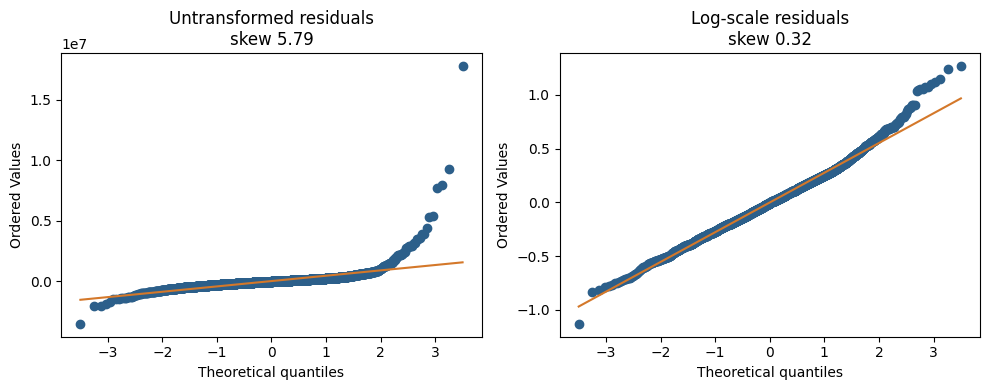

In [9]:
print(f"Residual skew, regular: {raw_model.resid.skew():.2f}")
print(f"Residual skew, log scale: {pd.Series(log_model.resid).skew():.2f}")

print("Regular regression:")
display(raw_model.summary())

print("Log-transformed regression:")
display(log_model.summary())

rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
panels = [
    (raw_model.resid, f"Untransformed residuals\nskew {raw_model.resid.skew():.2f}"),
    (log_model.resid, f"Log-scale residuals\nskew {pd.Series(log_model.resid).skew():.2f}")
]

for ax, (resid, title) in zip(axes, panels):
    sample = rng.choice(np.asarray(resid), size=min(3000, len(resid)), replace=False)
    stats.probplot(sample, dist="norm", plot=ax)
    ax.set_title(title)
    ax.get_lines()[0].set_color("#2c5f8a")
    ax.get_lines()[1].set_color("#d4782a")
fig.tight_layout()
plt.show()

### Feature Engineering

In [10]:
def tree_frame(frame):
    X = numeric_design(frame)
    listed_month = frame["date_listed"].dt.month.to_numpy()
    X["listed_month_sin"] = np.sin(2 * np.pi * listed_month / 12)
    X["listed_month_cos"] = np.cos(2 * np.pi * listed_month / 12)
    return X

tree_train = tree_frame(train)
tree_valid = tree_frame(valid)

log_sold = np.log(train["sold_price"].to_numpy())

In [11]:
tune_start = pd.Timestamp("2025-07-01")
fit_mask = (train["date_sold"] < tune_start).to_numpy()
X_fit = tree_train.iloc[fit_mask]
y_fit = np.log(train["sold_price"].to_numpy()[fit_mask])
X_tune = tree_train.iloc[~fit_mask]
sold_tune = train["sold_price"].to_numpy()[~fit_mask]
print(
    f"Parameter search: fit {fit_mask.sum():,} sales through June 2025, "
    f"score {(~fit_mask).sum():,} sales from July through November 2025"
)

def inner_mdape(model):
    model.fit(X_fit, y_fit)
    predicted = np.exp(model.predict(X_tune))
    error = np.abs(predicted - sold_tune) / sold_tune
    return round(float(np.median(error) * 100), 3)

def validation_score(name, model):
    model.fit(tree_train, log_sold)
    predicted = np.exp(model.predict(tree_valid))
    return add_score(name, predicted, valid["sold_price"])

Parameter search: fit 130,045 sales through June 2025, score 9,886 sales from July through November 2025


## XGBoost

In [12]:
xgb_candidates = list(ParameterGrid(
    {
        "max_depth": [4, 6, 8],
        "learning_rate": [0.05, 0.1],
        "n_estimators": [200, 400],
    }
))

xgb_candidates.extend([
    {
        "max_depth": 8,
        "learning_rate": 0.05,
        "n_estimators": 600,
    },
    {
        "max_depth": 8,
        "learning_rate": 0.03,
        "n_estimators": 600,
    },
    {
        "max_depth": 10,
        "learning_rate": 0.05,
        "n_estimators": 400,
    },
    {
        "max_depth": 10,
        "learning_rate": 0.05,
        "n_estimators": 600,
    },
])

xgb_rows = []

for params in xgb_candidates:
    score = inner_mdape(
        XGBRegressor(
            **params,
            min_child_weight=20,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_lambda=1.0,
            tree_method="hist",
            n_jobs=-1,
            random_state=0,
            verbosity=0,
        )
    )

    xgb_rows.append({**params, "inner_MdAPE": score})


xgb_table = pd.DataFrame(xgb_rows).sort_values(
    ["inner_MdAPE", "n_estimators", "max_depth", "learning_rate"]
).reset_index(drop=True)

display(xgb_table)
best_xgb = xgb_table.iloc[0]
validation_score(
    f"XGBoost, depth {int(best_xgb.max_depth)}, lr {best_xgb.learning_rate:g}, {int(best_xgb.n_estimators)} trees",
    XGBRegressor(
        n_estimators=int(best_xgb.n_estimators),
        max_depth=int(best_xgb.max_depth),
        learning_rate=float(best_xgb.learning_rate),
        min_child_weight=20,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        tree_method="hist",
        n_jobs=-1,
        random_state=0,
        verbosity=0,
    ),
)

,learning_rate,max_depth,n_estimators,inner_MdAPE
0,0.05,10,600,15.470
1,0.05,10,400,15.633
2,0.10,8,400,15.725
3,0.05,8,600,15.873
4,0.05,8,400,16.275
5,0.03,8,600,16.279
6,0.10,6,400,16.355
7,0.10,8,200,16.369
8,0.10,6,200,16.969
9,0.05,8,200,17.000


XGBoost, depth 10, lr 0.05, 600 trees: MdAPE 17.28%, MAPE 21.17%, median signed error +14.00%


{'model': 'XGBoost, depth 10, lr 0.05, 600 trees',
 'MdAPE': 17.28,
 'MAPE': 21.17,
 'median_signed_error': 14.0}

## CatBoost

In [14]:
from catboost import CatBoostRegressor

cat_candidates = list(ParameterGrid(
    {
        "depth": [6, 8],
        "learning_rate": [0.05, 0.1],
        "l2_leaf_reg": [3, 10],
    }
))

cat_candidates.extend([
    {
        "depth": 6,
        "learning_rate": 0.15,
        "l2_leaf_reg": 3,
    },
    {
        "depth": 6,
        "learning_rate": 0.15,
        "l2_leaf_reg": 1,
    },
])

cat_rows = []
for params in cat_candidates:
    score = inner_mdape(
        CatBoostRegressor(
            **params,
            iterations=300,
            loss_function="RMSE",
            random_seed=0,
            verbose=0,
            allow_writing_files=False,
            thread_count=-1,
        )
    )
    cat_rows.append({**params, "inner_MdAPE": score})
cat_table = pd.DataFrame(cat_rows).sort_values(
    ["inner_MdAPE", "depth", "l2_leaf_reg", "learning_rate"]
).reset_index(drop=True)
display(cat_table)
best_cat = cat_table.iloc[0]
validation_score(
    f"CatBoost, depth {int(best_cat.depth)}, lr {best_cat.learning_rate:g}, l2 {best_cat.l2_leaf_reg:g}",
    CatBoostRegressor(
        depth=int(best_cat.depth),
        learning_rate=float(best_cat.learning_rate),
        l2_leaf_reg=float(best_cat.l2_leaf_reg),
        iterations=300,
        loss_function="RMSE",
        random_seed=0,
        verbose=0,
        allow_writing_files=False,
        thread_count=-1,
    ),
)

CatBoost, depth 8, lr 0.1, l2 3: MdAPE 18.61%, MAPE 23.31%, median signed error +13.66%


,depth,l2_leaf_reg,learning_rate,inner_MdAPE
0,8,3,0.10,17.038
1,8,10,0.10,17.132
2,6,3,0.15,17.161
3,6,1,0.15,17.307
4,6,10,0.10,17.654
5,6,3,0.10,17.720
6,8,3,0.05,17.892
7,8,10,0.05,17.941
8,6,10,0.05,18.322
9,6,3,0.05,18.347


## Random Forest

In [13]:
rf_rows = []
for params in ParameterGrid(
    {
        "max_depth": [12, 20, 32],
        "min_samples_leaf": [5, 20],
    }
):
    score = inner_mdape(
        RandomForestRegressor(
            **params,
            n_estimators=200,
            max_features=0.5,
            n_jobs=-1,
            random_state=0,
        )
    )
    rf_rows.append({**params, "inner_MdAPE": score})

rf_table = pd.DataFrame(rf_rows).sort_values(
    ["inner_MdAPE", "max_depth", "min_samples_leaf"],
    ascending=[True, True, False],
).reset_index(drop=True)

display(rf_table)
best_rf = rf_table.iloc[0]
validation_score(
    f"Random Forest, depth {int(best_rf.max_depth)}, leaf {int(best_rf.min_samples_leaf)}",
    RandomForestRegressor(
        n_estimators=200,
        max_depth=int(best_rf.max_depth),
        min_samples_leaf=int(best_rf.min_samples_leaf),
        max_features=0.5,
        n_jobs=-1,
        random_state=0,
    ),
)

,max_depth,min_samples_leaf,inner_MdAPE
0,32,5,17.442
1,20,5,17.605
2,32,20,18.387
3,20,20,18.444
4,12,5,19.118
5,12,20,19.207


Random Forest, depth 32, leaf 5: MdAPE 18.95%, MAPE 23.63%, median signed error +13.93%


{'model': 'Random Forest, depth 32, leaf 5',
 'MdAPE': 18.95,
 'MAPE': 23.63,
 'median_signed_error': 13.93}

## V1: Recent community dollars per square foot

Square feet times the median sold dollars per square foot of earlier sales in the same community and house type. Only sales from a recent window of months before the listing month are used. Fewer than 30 sales falls back to the house type, then to the city. The window is chosen on sales from July through November 2025. December 2025 through May 2026 is scored once, with the price levels taken from sales before December.


In [30]:
def month_ord(dates):
    return (dates.dt.year * 12 + dates.dt.month).to_numpy()


def recent_psf_table(reference, group_columns, window):
    history = reference.loc[:, group_columns].copy()
    history["month_ord"] = month_ord(reference["date_sold"])
    history["value"] = (reference["sold_price"] / reference["square_feet"]).to_numpy(dtype=float)
    history = history.replace([np.inf, -np.inf], np.nan).dropna()
    last_month = int(history["month_ord"].max())
    query_ords = np.arange(int(history["month_ord"].min()) - 24, last_month + 18)
    pieces = []
    for key, group in history.groupby(group_columns, observed=True, sort=False):
        group = group.sort_values("month_ord")
        sale_ords = group["month_ord"].to_numpy()
        values = group["value"].to_numpy()
        medians = np.full(len(query_ords), np.nan)
        counts = np.zeros(len(query_ords), dtype=float)
        for i, query in enumerate(query_ords):
            end = int(np.searchsorted(sale_ords, query, side="left"))
            if end == 0:
                continue
            start = int(np.searchsorted(sale_ords, query - window, side="left"))
            if start >= end:
                last = int(sale_ords[end - 1])
                start = int(np.searchsorted(sale_ords, last - window + 1, side="left"))
            medians[i] = float(np.median(values[start:end]))
            counts[i] = end - start
        key = key if isinstance(key, tuple) else (key,)
        piece = {"month_ord": query_ords, "median": medians, "count": counts}
        for column, value in zip(group_columns, key):
            piece[column] = value
        pieces.append(pd.DataFrame(piece))
    return pd.concat(pieces, ignore_index=True)


def lookup_past(query, table, group_columns):
    keys = query.loc[:, list(group_columns)].copy()
    keys["month_ord"] = month_ord(query["date_listed"])
    merged = keys.merge(table, on=list(group_columns) + ["month_ord"], how="left")
    if len(merged) != len(query):
        raise ValueError("past-median lookup changed the number of rows")
    median = merged["median"].to_numpy(dtype=float)
    count = merged["count"].fillna(0).to_numpy(dtype=float)
    return median, count


def psf_bundle(reference, window):
    usable = reference[(reference["sold_price"] > 0) & (reference["square_feet"] > 0)].copy()
    usable["_all"] = "all"
    return {
        "frame": usable,
        "fallback": float(np.median(usable["sold_price"] / usable["square_feet"])),
        "community": recent_psf_table(usable, ["community", "house_type_name"], window),
        "type": recent_psf_table(usable, ["house_type_name"], window),
        "city": recent_psf_table(usable, ["_all"], window),
    }


def price_level(frame, bundle):
    query = frame.copy()
    query["_all"] = "all"
    community_median, community_count = lookup_past(query, bundle["community"], ["community", "house_type_name"])
    type_median, type_count = lookup_past(query, bundle["type"], ["house_type_name"])
    city_median, city_count = lookup_past(query, bundle["city"], ["_all"])
    level = np.where(community_count >= 30, community_median, np.where(type_count >= 30, type_median, city_median))
    level = np.where(np.isfinite(level) & (level > 0), level, bundle["fallback"])
    return level, community_count >= 30


def anchor_price(frame, bundle):
    level, community_hit = price_level(frame, bundle)
    return level * frame["square_feet"].to_numpy(dtype=float), community_hit


screen = train[train["date_sold"] >= "2025-07-01"]
window_rows = []
for window, label in [(3, "3 months"), (6, "6 months"), (12, "12 months"), (24, "24 months"), (240, "all history")]:
    print(f"screening {label}", flush=True)
    bundle = psf_bundle(train, window)
    predicted, community_hit = anchor_price(screen, bundle)
    row = {
        "window": label,
        "months": window,
        "community_share": round(100 * float(community_hit.mean()), 1),
        **percentage_scores(predicted, screen["sold_price"]),
    }
    window_rows.append(row)
    print(
        f"{label}: MdAPE {row['MdAPE']:.2f}, MAPE {row['MAPE']:.2f}, "
        f"signed {row['median_signed_error']:+.2f}, community {row['community_share']:.1f}%",
        flush=True,
    )
window_table = pd.DataFrame(window_rows).sort_values(["MdAPE", "MAPE"]).reset_index(drop=True)
display(window_table)
chosen_window = int(window_table.iloc[0]["months"])
chosen_label = window_table.iloc[0]["window"]
print(f"Chosen window: {chosen_label}")

v1_bundle = psf_bundle(train, chosen_window)
v1_hat, v1_community = anchor_price(valid, v1_bundle)
print(
    f"Validation community level: {100 * float(v1_community.mean()):.1f}% of homes. "
    f"Type or city fallback: {100 * float((~v1_community).mean()):.1f}%."
)
add_score(f"V1 recent community $/sqft, {chosen_label}", v1_hat, valid["sold_price"])
if chosen_window != 240:
    history_bundle = psf_bundle(train, 240)
    history_hat, _ = anchor_price(valid, history_bundle)
    add_score("V1 check, all-history community $/sqft", history_hat, valid["sold_price"])
all_history_score = next(
    row["MdAPE"] for row in scores if "all history" in row["model"] or "all-history" in row["model"]
)
if abs(all_history_score - 17.07) > 0.8:
    raise RuntimeError(f"all-history MdAPE {all_history_score} is far from the EDA baseline 17.07")


screening 3 months
3 months: MdAPE 17.21, MAPE 24.19, signed +4.30, community 35.0%
screening 6 months
6 months: MdAPE 16.19, MAPE 22.78, signed +6.54, community 61.0%
screening 12 months
12 months: MdAPE 15.33, MAPE 21.46, signed +6.95, community 79.9%
screening 24 months
24 months: MdAPE 15.70, MAPE 21.64, signed +9.18, community 89.8%
screening all history
all history: MdAPE 16.42, MAPE 22.44, signed +11.97, community 96.9%


,window,months,community_share,MdAPE,MAPE,median_signed_error
0,12 months,12,79.9,15.33,21.46,6.95
1,24 months,24,89.8,15.70,21.64,9.18
2,6 months,6,61.0,16.19,22.78,6.54
3,all history,240,96.9,16.42,22.44,11.97
4,3 months,3,35.0,17.21,24.19,4.30


Chosen window: 12 months
Validation community level: 76.5% of homes. Type or city fallback: 23.5%.
V1 recent community $/sqft, 12 months: MdAPE 15.60%, MAPE 20.80%, median signed error +3.71%
V1 check, all-history community $/sqft: MdAPE 17.07%, MAPE 22.23%, median signed error +10.84%


## V2: Level shift on the recent price

V1's all-history price sits above the 2025 market. The shift is the median log miss of the chosen V1 window on September through November 2025, using price levels built only from sales before September. The December 2025 through May 2026 prediction uses price levels from all sales before December, multiplied by exp(−shift).


In [31]:
early = train[train["date_sold"] < "2025-09-01"]
recent_check = train[train["date_sold"] >= "2025-09-01"]
early_bundle = psf_bundle(early, chosen_window)
recent_anchor, _ = anchor_price(recent_check, early_bundle)
v2_shift = float(np.median(np.log(recent_anchor) - np.log(recent_check["sold_price"].to_numpy())))
print(f"September-November shift: predictions high by {100 * (np.exp(v2_shift) - 1):+.2f}%")
v2_hat = v1_hat * np.exp(-v2_shift)
add_score(f"V2 V1 with level shift, {chosen_label}", v2_hat, valid["sold_price"])


September-November shift: predictions high by +7.15%
V2 V1 with level shift, 12 months: MdAPE 15.22%, MAPE 19.40%, median signed error -3.22%


## V3: LightGBM on the gap around V1

The target is log(sold price / V1 anchor). The features are the numeric size, lot, and coordinate fields, the listing-month sine and cosine, the log of the recent community price and of the 3-month and 12-month citywide prices, plus house type, style, community, and municipality as categories. Category levels and price tables come from sales before December 2025. The trees use the list-aware settings: 127 leaves, learning rate 0.03, 700 trees.


In [32]:
from lightgbm import LGBMRegressor

GAP_CATEGORIES = ["house_type_name", "house_style", "community", "municipality"]
PHRASE_PATTERNS = [
    ("as_is", r"as-is|as is"),
    ("turnkey", r"turnkey"),
    ("potential", r"potential"),
    ("original", r"original"),
    ("finished", r"finished"),
    ("renovated", r"renovat"),
    ("needs_work", r"needs work"),
    ("stunning", r"stunning|beautiful|gorgeous|spectacular"),
]
gap_lgb = dict(
    num_leaves=127,
    learning_rate=0.03,
    n_estimators=700,
    min_child_samples=20,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    random_state=0,
    n_jobs=-1,
    verbosity=-1,
)


def city_bundle(reference, window):
    usable = reference[(reference["sold_price"] > 0) & (reference["square_feet"] > 0)].copy()
    usable["_all"] = "all"
    return {
        "frame": usable,
        "fallback": float(np.median(usable["sold_price"] / usable["square_feet"])),
        "city": recent_psf_table(usable, ["_all"], window),
    }


def city_level(frame, bundle):
    query = frame.copy()
    query["_all"] = "all"
    median, count = lookup_past(query, bundle["city"], ["_all"])
    return np.where(np.isfinite(median) & (median > 0), median, bundle["fallback"])


def phrase_frame(frame):
    text = frame["remarks"].fillna("").str.lower()
    columns = pd.DataFrame(index=frame.index)
    for name, pattern in PHRASE_PATTERNS:
        columns[name] = text.str.contains(pattern, regex=True).astype(float).to_numpy()
    return columns


def gap_design(frame, anchor_bundle, city3, city12, levels, use_phrases):
    level, _ = price_level(frame, anchor_bundle)
    X = tree_frame(frame)
    X["log_community_psf"] = np.log(level)
    X["log_city_psf_3"] = np.log(city_level(frame, city3))
    X["log_city_psf_12"] = np.log(city_level(frame, city12))
    for column in GAP_CATEGORIES:
        X[column] = pd.Categorical(frame[column].to_numpy(), categories=levels[column])
    if use_phrases:
        phrases = phrase_frame(frame)
        for column in phrases.columns:
            X[column] = phrases[column].to_numpy()
    anchor = level * frame["square_feet"].to_numpy(dtype=float)
    return X, anchor


def category_levels(reference):
    return {column: pd.Index(reference[column].dropna().unique()) for column in GAP_CATEGORIES}


def fit_gap(fit_frame, reference, window, use_phrases):
    anchor_bundle = psf_bundle(reference, window)
    city3 = city_bundle(reference, 3)
    city12 = city_bundle(reference, 12)
    levels = category_levels(reference)
    X, anchor = gap_design(fit_frame, anchor_bundle, city3, city12, levels, use_phrases)
    model = LGBMRegressor(**gap_lgb)
    model.fit(X, np.log(fit_frame["sold_price"].to_numpy() / anchor), categorical_feature=GAP_CATEGORIES)
    return model, anchor_bundle, city3, city12, levels


def predict_gap(model, frame, anchor_bundle, city3, city12, levels, use_phrases):
    X, anchor = gap_design(frame, anchor_bundle, city3, city12, levels, use_phrases)
    return anchor * np.exp(model.predict(X))


print("Fitting V3", flush=True)
v3_model, v3_bundle, v3_city3, v3_city12, v3_levels = fit_gap(train, train, chosen_window, False)
v3_hat = predict_gap(v3_model, valid, v3_bundle, v3_city3, v3_city12, v3_levels, False)
add_score(f"V3 LightGBM on the V1 gap, {chosen_label}", v3_hat, valid["sold_price"])


Fitting V3
V3 LightGBM on the V1 gap, 12 months: MdAPE 9.40%, MAPE 12.13%, median signed error +1.03%


## V4: Level shift on V3

The shift is the median log miss of a V3 model fit only on sales before September 2025, scored on September through November 2025. Price levels for that fit come from the sales before September. The model is then refit on all sales before December and the same shift is applied.


In [33]:
print("Fitting V4 shift model", flush=True)
v4_early_model, v4_early_bundle, v4_early_city3, v4_early_city12, v4_early_levels = fit_gap(
    early, early, chosen_window, False
)
v4_recent_hat = predict_gap(
    v4_early_model, recent_check, v4_early_bundle, v4_early_city3, v4_early_city12, v4_early_levels, False
)
v4_shift = float(np.median(np.log(v4_recent_hat) - np.log(recent_check["sold_price"].to_numpy())))
print(f"September-November shift: predictions high by {100 * (np.exp(v4_shift) - 1):+.2f}%")
print("Refitting V4", flush=True)
v4_model, v4_bundle, v4_city3, v4_city12, v4_levels = fit_gap(train, train, chosen_window, False)
v4_hat = predict_gap(v4_model, valid, v4_bundle, v4_city3, v4_city12, v4_levels, False) * np.exp(-v4_shift)
add_score(f"V4 V3 with level shift, {chosen_label}", v4_hat, valid["sold_price"])


Fitting V4 shift model
September-November shift: predictions high by +2.34%
Refitting V4
V4 V3 with level shift, 12 months: MdAPE 9.23%, MAPE 11.88%, median signed error -1.28%


## V5: Condition phrases

V4's features plus indicators read from the remarks: as-is, turnkey, potential, original, finished, renovated, needs work, and stunning or beautiful. The level shift is measured again for this feature set, on September through November 2025, from a model fit only before September.


In [34]:
print("Fitting V5 shift model", flush=True)
v5_early_model, v5_early_bundle, v5_early_city3, v5_early_city12, v5_early_levels = fit_gap(
    early, early, chosen_window, True
)
v5_recent_hat = predict_gap(
    v5_early_model, recent_check, v5_early_bundle, v5_early_city3, v5_early_city12, v5_early_levels, True
)
v5_shift = float(np.median(np.log(v5_recent_hat) - np.log(recent_check["sold_price"].to_numpy())))
print(f"September-November shift: predictions high by {100 * (np.exp(v5_shift) - 1):+.2f}%")
print("Refitting V5", flush=True)
v5_model, v5_bundle, v5_city3, v5_city12, v5_levels = fit_gap(train, train, chosen_window, True)
v5_hat = predict_gap(v5_model, valid, v5_bundle, v5_city3, v5_city12, v5_levels, True) * np.exp(-v5_shift)
add_score(f"V5 condition phrases with level shift, {chosen_label}", v5_hat, valid["sold_price"])


Fitting V5 shift model
September-November shift: predictions high by +2.43%
Refitting V5
V5 condition phrases with level shift, 12 months: MdAPE 8.97%, MAPE 11.19%, median signed error -1.33%


## V6: Blended community price and a partial level shift

V5 jumps from the community median to the type median at 30 sales, and it applies the whole three-month level shift. Here the community median is blended with the type median, with the community's weight equal to its sale count divided by that count plus a strength. The shift is multiplied by a weight between 0 and 1. The strength, the shift weight, and a recheck of the 6-, 12-, and 24-month windows are chosen on July through November 2025. Extra remark flags are kept only if they lower that same error. December 2025 through May 2026 is scored once.


In [36]:
def v6_level(frame, bundle, strength):
    if strength is None:
        level, _ = price_level(frame, bundle)
        return level
    query = frame.copy()
    query["_all"] = "all"
    community_median, community_count = lookup_past(query, bundle["community"], ["community", "house_type_name"])
    type_median, type_count = lookup_past(query, bundle["type"], ["house_type_name"])
    city_median, city_count = lookup_past(query, bundle["city"], ["_all"])
    type_level = np.where(type_count >= 30, type_median, city_median)
    community_ok = np.isfinite(community_median) & (community_median > 0) & (community_count > 0)
    denom = community_count + strength
    ratio = np.divide(
        community_count,
        denom,
        out=np.zeros(len(community_count), dtype=float),
        where=denom > 0,
    )
    weight = np.where(community_ok, ratio, 0.0)
    blended = weight * np.where(community_ok, community_median, type_level) + (1.0 - weight) * type_level
    return np.where(np.isfinite(blended) & (blended > 0), blended, bundle["fallback"])


def v6_design(frame, anchor_bundle, city3, city12, levels, phrases, strength):
    level = v6_level(frame, anchor_bundle, strength)
    X = tree_frame(frame)
    X["log_community_psf"] = np.log(level)
    X["log_city_psf_3"] = np.log(city_level(frame, city3))
    X["log_city_psf_12"] = np.log(city_level(frame, city12))
    for column in GAP_CATEGORIES:
        X[column] = pd.Categorical(frame[column].to_numpy(), categories=levels[column])
    text = frame["remarks"].fillna("").str.lower()
    for name, pattern in phrases:
        X[name] = text.str.contains(pattern, regex=True).astype(float).to_numpy()
    anchor = level * frame["square_feet"].to_numpy(dtype=float)
    return X, anchor


def v6_fit(fit_frame, anchor_bundle, city3, city12, levels, phrases, strength):
    X, anchor = v6_design(fit_frame, anchor_bundle, city3, city12, levels, phrases, strength)
    model = LGBMRegressor(**gap_lgb)
    model.fit(
        X,
        np.log(fit_frame["sold_price"].to_numpy() / anchor),
        categorical_feature=GAP_CATEGORIES,
    )
    return model


def v6_predict(model, frame, anchor_bundle, city3, city12, levels, phrases, strength):
    X, anchor = v6_design(frame, anchor_bundle, city3, city12, levels, phrases, strength)
    return anchor * np.exp(model.predict(X))


def v6_prepare(reference, window):
    return (
        psf_bundle(reference, window),
        city_bundle(reference, 3),
        city_bundle(reference, 12),
        category_levels(reference),
    )


def v6_screen(window, strengths, phrases):
    early_ref = train[train["date_sold"] < "2025-04-01"]
    fit_ref = train[train["date_sold"] < "2025-07-01"]
    shift_rows = train[(train["date_sold"] >= "2025-04-01") & (train["date_sold"] < "2025-07-01")]
    score_rows = train[train["date_sold"] >= "2025-07-01"]
    early_pack = v6_prepare(early_ref, window)
    full_pack = v6_prepare(train, window)
    rows = []
    for strength_name, strength in strengths:
        print(f"window {window}, {strength_name}: shift fit", flush=True)
        shift_model = v6_fit(early_ref, *early_pack, phrases, strength)
        shift_hat = v6_predict(shift_model, shift_rows, *early_pack, phrases, strength)
        shift = float(np.median(np.log(shift_hat) - np.log(shift_rows["sold_price"].to_numpy())))
        print(f"window {window}, {strength_name}: July fit", flush=True)
        model = v6_fit(fit_ref, *full_pack, phrases, strength)
        base_hat = v6_predict(model, score_rows, *full_pack, phrases, strength)
        for weight in [0.0, 0.25, 0.5, 0.75, 1.0]:
            hat = base_hat * np.exp(-weight * shift)
            row = {
                "window": window,
                "strength": strength_name,
                "shift_weight": weight,
                "phrases": "extra" if len(phrases) > len(PHRASE_PATTERNS) else "base",
                **percentage_scores(hat, score_rows["sold_price"]),
            }
            rows.append(row)
            print(
                f"  weight {weight:g}: MdAPE {row['MdAPE']:.2f}, "
                f"signed {row['median_signed_error']:+.2f}",
                flush=True,
            )
    return pd.DataFrame(rows)


V6_STRENGTHS = [
    ("hard 30", None),
    ("blend 0", 0.0),
    ("blend 10", 10.0),
    ("blend 30", 30.0),
    ("blend 100", 100.0),
]
V6_EXTRA_PHRASES = PHRASE_PATTERNS + [
    ("investor", r"\binvestors?\b"),
    ("motivated", r"\bmotivated\b"),
    ("redone", r"\bredone\b|\bredo\b"),
    ("dated", r"\bdated\b"),
    ("worn", r"\bworn\b"),
]
print(f"July-November selection sales: {(train['date_sold'] >= '2025-07-01').sum():,}", flush=True)
v6_base_screen = pd.concat(
    [v6_screen(window, V6_STRENGTHS, PHRASE_PATTERNS) for window in (12, 6, 24)],
    ignore_index=True,
)
v6_base_screen = v6_base_screen.sort_values(["MdAPE", "MAPE", "shift_weight"]).reset_index(drop=True)
display(v6_base_screen)
v6_choice = v6_base_screen.iloc[0]
v6_window = int(v6_choice["window"])
v6_strength_name = v6_choice["strength"]
v6_strength = dict(V6_STRENGTHS)[v6_strength_name]
v6_weight = float(v6_choice["shift_weight"])
print(
    f"Base choice: {v6_window} months, {v6_strength_name}, shift weight {v6_weight:g}, "
    f"July-November MdAPE {v6_choice['MdAPE']:.2f}"
)

v6_extra_screen = v6_screen(v6_window, [(v6_strength_name, v6_strength)], V6_EXTRA_PHRASES)
v6_extra_screen = v6_extra_screen.sort_values(["MdAPE", "MAPE", "shift_weight"]).reset_index(drop=True)
display(v6_extra_screen)
v6_phrases = PHRASE_PATTERNS
v6_phrase_name = "base"
if v6_extra_screen.iloc[0]["MdAPE"] < v6_choice["MdAPE"]:
    v6_phrases = V6_EXTRA_PHRASES
    v6_phrase_name = "extra"
    v6_weight = float(v6_extra_screen.iloc[0]["shift_weight"])
    print(
        f"Extra remarks kept. Shift weight {v6_weight:g}, "
        f"July-November MdAPE {v6_extra_screen.iloc[0]['MdAPE']:.2f}"
    )
else:
    print(
        f"Extra remarks left out. July-November MdAPE {v6_extra_screen.iloc[0]['MdAPE']:.2f} "
        f"versus {v6_choice['MdAPE']:.2f} for the base phrases."
    )

print("Fitting the December V6 model", flush=True)
v6_early = train[train["date_sold"] < "2025-09-01"]
v6_check = train[train["date_sold"] >= "2025-09-01"]
v6_early_pack = v6_prepare(v6_early, v6_window)
v6_shift_model = v6_fit(v6_early, *v6_early_pack, v6_phrases, v6_strength)
v6_check_hat = v6_predict(v6_shift_model, v6_check, *v6_early_pack, v6_phrases, v6_strength)
v6_shift = float(np.median(np.log(v6_check_hat) - np.log(v6_check["sold_price"].to_numpy())))
print(
    f"September-November shift before the weight: predictions high by "
    f"{100 * (np.exp(v6_shift) - 1):+.2f}%. Applied weight {v6_weight:g}."
)
v6_full_pack = v6_prepare(train, v6_window)
v6_model = v6_fit(train, *v6_full_pack, v6_phrases, v6_strength)
v6_hat = v6_predict(v6_model, valid, *v6_full_pack, v6_phrases, v6_strength) * np.exp(-v6_weight * v6_shift)
v6_window_label = {6: "6 months", 12: "12 months", 24: "24 months"}[v6_window]
v6_name = (
    f"V6 {v6_strength_name}, shift weight {v6_weight:g}, {v6_window_label}"
    + (", extra remarks" if v6_phrase_name == "extra" else "")
)
add_score(v6_name, v6_hat, valid["sold_price"])


July-November selection sales: 9,886
window 12, hard 30: shift fit
window 12, hard 30: July fit
  weight 0: MdAPE 9.33, signed +5.27
  weight 0.25: MdAPE 9.01, signed +4.49
  weight 0.5: MdAPE 8.77, signed +3.73
  weight 0.75: MdAPE 8.59, signed +2.96
  weight 1: MdAPE 8.41, signed +2.21
window 12, blend 0: shift fit
window 12, blend 0: July fit
  weight 0: MdAPE 9.52, signed +5.84
  weight 0.25: MdAPE 9.19, signed +5.03
  weight 0.5: MdAPE 8.95, signed +4.22
  weight 0.75: MdAPE 8.74, signed +3.42
  weight 1: MdAPE 8.51, signed +2.63
window 12, blend 10: shift fit
window 12, blend 10: July fit
  weight 0: MdAPE 9.32, signed +5.39
  weight 0.25: MdAPE 9.12, signed +4.66
  weight 0.5: MdAPE 8.85, signed +3.94
  weight 0.75: MdAPE 8.71, signed +3.22
  weight 1: MdAPE 8.57, signed +2.50
window 12, blend 30: shift fit
window 12, blend 30: July fit
  weight 0: MdAPE 9.34, signed +5.23
  weight 0.25: MdAPE 9.10, signed +4.52
  weight 0.5: MdAPE 8.89, signed +3.81
  weight 0.75: MdAPE 8.72, s

,window,strength,shift_weight,phrases,MdAPE,MAPE,median_signed_error
0,12,hard 30,1.00,base,8.41,11.18,2.21
1,24,hard 30,1.00,base,8.48,11.10,2.43
2,12,blend 0,1.00,base,8.51,11.26,2.63
3,24,blend 10,1.00,base,8.53,11.16,2.46
4,24,blend 100,1.00,base,8.54,11.11,2.21
5,12,blend 100,1.00,base,8.55,11.26,2.66
6,6,blend 10,1.00,base,8.56,11.39,2.80
7,24,blend 0,1.00,base,8.57,11.25,2.73
8,12,blend 10,1.00,base,8.57,11.30,2.50
9,6,blend 30,1.00,base,8.59,11.35,2.77


Base choice: 12 months, hard 30, shift weight 1, July-November MdAPE 8.41
window 12, hard 30: shift fit
window 12, hard 30: July fit
  weight 0: MdAPE 9.16, signed +5.28
  weight 0.25: MdAPE 8.88, signed +4.45
  weight 0.5: MdAPE 8.68, signed +3.63
  weight 0.75: MdAPE 8.50, signed +2.81
  weight 1: MdAPE 8.33, signed +2.00


,window,strength,shift_weight,phrases,MdAPE,MAPE,median_signed_error
0,12,hard 30,1.00,extra,8.33,11.05,2.00
1,12,hard 30,0.75,extra,8.50,11.27,2.81
2,12,hard 30,0.50,extra,8.68,11.53,3.63
3,12,hard 30,0.25,extra,8.88,11.82,4.45
4,12,hard 30,0.00,extra,9.16,12.16,5.28


Extra remarks kept. Shift weight 1, July-November MdAPE 8.33
Fitting the December V6 model
September-November shift before the weight: predictions high by +2.23%. Applied weight 1.
V6 hard 30, shift weight 1, 12 months, extra remarks: MdAPE 8.85%, MAPE 11.09%, median signed error -0.76%


## V7: Earlier sales in the same building

V6 prices a home from its community. V7 also uses earlier sales at the same coordinates and house type, which is a condo building or a house's lot. A sale counts only when it closed before the home was listed, and the home's own listing number is removed. Each earlier price is moved onto the listing month with that property type's market index: the monthly median log dollars per square foot, smoothed over three months, from earlier months only.

The variant is chosen on July through November 2025. That comparison fits only on sales before July, and the comps in it also close before July, so a July-November price is neither a training row nor a comparable. The shift weight, 0 or 1, is chosen on that same slice. December 2025 through May 2026 is scored once, after the choice is fixed, and those sales are not comps in that fit.


In [38]:
def _pin_key(frame):
    lat = np.round(frame["latitude"].to_numpy(dtype=float), 6)
    lon = np.round(frame["longitude"].to_numpy(dtype=float), 6)
    typ = frame["house_type_name"].astype(str).to_numpy()
    return pd.Series(
        [f"{a:.6f}|{b:.6f}|{c}" for a, b, c in zip(lat, lon, typ)],
        index=frame.index,
    )


def _repeat_key(frame):
    pin = _pin_key(frame).to_numpy()
    beds = frame["bedrooms"].astype(str).to_numpy()
    baths = frame["washrooms"].astype(str).to_numpy()
    area = frame["house_area"].astype(str).to_numpy()
    return pd.Series(
        [f"{p}|{a}|{b}|{c}" for p, a, b, c in zip(pin, beds, baths, area)],
        index=frame.index,
    )


def _index_tables(types, ords, log_psf):
    """Monthly type index known at the start of each month: a 3-month median of earlier months."""
    frame = pd.DataFrame({"typ": types, "ord": ords, "log_psf": log_psf})
    monthly = frame.groupby(["typ", "ord"], sort=False)["log_psf"].median()
    tables = {}
    for typ, series in monthly.groupby(level=0):
        values = series.droplevel(0).sort_index()
        # Extend past the last sale so a later listing month is in the table.
        # Months with no sales keep the previous month's median. The shift then
        # makes month m use only months before m.
        span = np.arange(int(values.index.min()), int(values.index.max()) + 1 + 24)
        level = values.reindex(span).ffill()
        known = level.rolling(3, min_periods=1).median().shift(1)
        tables[typ] = (span.astype(np.int32), known.to_numpy(dtype=float))
    return tables


def _index_at(tables, types, ords):
    out = np.full(len(ords), np.nan, dtype=float)
    if len(ords) == 0:
        return out
    type_arr = np.asarray(types)
    order = np.argsort(type_arr, kind="mergesort")
    sorted_types = type_arr[order]
    breaks = np.flatnonzero(np.r_[True, sorted_types[1:] != sorted_types[:-1], True])
    for start, stop in zip(breaks[:-1], breaks[1:]):
        typ = sorted_types[start]
        table = tables.get(typ)
        if table is None:
            continue
        span, known = table
        pos = order[start:stop]
        query = ords[pos]
        loc = np.searchsorted(span, query)
        in_span = (loc < len(span)) & (loc >= 0) & (span[np.clip(loc, 0, len(span) - 1)] == query)
        out[pos[in_span]] = known[loc[in_span]]
        after = query > span[-1]
        if np.any(after):
            finite = np.isfinite(known)
            if np.any(finite):
                out[pos[after]] = known[np.flatnonzero(finite)[-1]]
    return out


def _groups(keys, dates, factor, ml_num):
    order = np.lexsort((dates, keys))
    keys = keys[order]
    dates = dates[order]
    factor = factor[order]
    ml_num = ml_num[order]
    groups = {}
    if len(keys) == 0:
        return groups
    breaks = np.flatnonzero(np.r_[True, keys[1:] != keys[:-1], True])
    for start, stop in zip(breaks[:-1], breaks[1:]):
        groups[keys[start]] = (dates[start:stop], factor[start:stop], ml_num[start:stop])
    return groups


def building_history(reference):
    """Sales a later listing is allowed to see. The index at a month uses only earlier months."""
    usable = reference[(reference["sold_price"] > 0) & (reference["square_feet"] > 0)].copy()
    usable = usable.dropna(subset=["latitude", "longitude", "house_type_name", "date_sold", "ml_num"])
    usable = usable.sort_values(["date_sold", "ml_num"])
    psf = usable["sold_price"].to_numpy(dtype=float) / usable["square_feet"].to_numpy(dtype=float)
    log_psf = np.log(psf)
    ords = (usable["date_sold"].dt.year * 12 + usable["date_sold"].dt.month).to_numpy(dtype=np.int32)
    types = usable["house_type_name"].astype(str).to_numpy()
    tables = _index_tables(types, ords, log_psf)
    sale_index = _index_at(tables, types, ords)
    keep = np.isfinite(sale_index) & np.isfinite(psf) & (psf > 0)
    usable = usable.loc[keep]
    factor = psf[keep] * np.exp(-sale_index[keep])
    dates = usable["date_sold"].to_numpy(dtype="datetime64[ns]")
    ml_num = usable["ml_num"].astype(str).to_numpy()
    return {
        "index": tables,
        "building": _groups(_pin_key(usable).to_numpy(), dates, factor, ml_num),
        "repeat": _groups(_repeat_key(usable).to_numpy(), dates, factor, ml_num),
        "max_sold": dates.max() if len(dates) else np.datetime64("NaT"),
        "ids": set(ml_num),
    }


def building_features(homes, history):
    """Median and latest reindexed $/sqft at the same pin, and the latest sale of the same home.

    A comp must have sold strictly before date_listed. The home's own ml_num is removed.
    Prices are multiplied by the type index of the listing month and divided by the index
    of the sale month. Both indexes were built from earlier months only.
    """
    n = len(homes)
    count = np.zeros(n, dtype=np.int32)
    median_psf = np.full(n, np.nan)
    last_psf = np.full(n, np.nan)
    days = np.full(n, np.nan)
    repeat_psf = np.full(n, np.nan)
    repeat_days = np.full(n, np.nan)
    listed = homes["date_listed"].to_numpy(dtype="datetime64[ns]")
    mls = homes["ml_num"].astype(str).to_numpy()
    list_ord = (homes["date_listed"].dt.year * 12 + homes["date_listed"].dt.month).to_numpy(dtype=np.int32)
    index_now = _index_at(history["index"], homes["house_type_name"].astype(str).to_numpy(), list_ord)

    def fill(groups, key, into_count, into_median, into_last, into_days, want_median):
        keys = key.to_numpy()
        order = np.argsort(keys, kind="mergesort")
        sorted_keys = keys[order]
        if len(sorted_keys) == 0:
            return
        breaks = np.flatnonzero(np.r_[True, sorted_keys[1:] != sorted_keys[:-1], True])
        for start, stop in zip(breaks[:-1], breaks[1:]):
            group = groups.get(sorted_keys[start])
            if group is None:
                continue
            g_dates, g_factor, g_ml = group
            pos = order[start:stop]
            rights = np.searchsorted(g_dates, listed[pos], side="left")
            for j, right in enumerate(rights):
                p = pos[j]
                if right <= 0 or not np.isfinite(index_now[p]):
                    continue
                keep = g_ml[:right] != mls[p]
                if not np.any(keep):
                    continue
                kept_dates = g_dates[:right][keep]
                kept_factor = g_factor[:right][keep]
                finite = np.isfinite(kept_factor)
                if not np.any(finite):
                    continue
                kept_dates = kept_dates[finite]
                kept_factor = kept_factor[finite]
                if np.any(kept_dates >= listed[p]):
                    raise RuntimeError("building comp sold on or after the listing date")
                scale = np.exp(index_now[p])
                into_count[p] = len(kept_factor)
                into_last[p] = scale * kept_factor[-1]
                into_days[p] = (listed[p] - kept_dates[-1]) / np.timedelta64(1, "D")
                if want_median:
                    into_median[p] = scale * float(np.median(kept_factor))

    fill(history["building"], _pin_key(homes), count, median_psf, last_psf, days, True)
    repeat_count = np.zeros(n, dtype=np.int32)
    fill(history["repeat"], _repeat_key(homes), repeat_count, repeat_psf, repeat_psf, repeat_days, False)
    if np.any((count > 0) & ~(days > 0)):
        raise RuntimeError("building comp is not strictly earlier than the listing")
    if np.any((repeat_count > 0) & ~(repeat_days > 0)):
        raise RuntimeError("repeat-sale comp is not strictly earlier than the listing")
    return pd.DataFrame(
        {
            "count": count,
            "median_psf": median_psf,
            "last_psf": last_psf,
            "days": days,
            "repeat_count": repeat_count,
            "repeat_psf": repeat_psf,
            "repeat_days": repeat_days,
        },
        index=homes.index,
    )


def assert_history_before(history, cutoff):
    sold = pd.Timestamp(history["max_sold"])
    if pd.isna(sold) or sold >= pd.Timestamp(cutoff):
        raise RuntimeError(f"comp history includes a sale on or after {cutoff}")


def assert_index_uses_only_earlier_sales():
    """A listing in 2023 must get the same type index with or without 2024-2025 sales."""
    cutoff = pd.Timestamp("2024-01-01")
    sample = train[train["date_listed"] < cutoff]
    sample = sample.sample(2000, random_state=0)
    ords = (sample["date_listed"].dt.year * 12 + sample["date_listed"].dt.month).to_numpy(dtype=np.int32)
    types = sample["house_type_name"].astype(str).to_numpy()
    full = _index_at(building_history(train)["index"], types, ords)
    past = _index_at(building_history(train[train["date_sold"] < cutoff])["index"], types, ords)
    if np.any(np.isfinite(full) != np.isfinite(past)):
        raise RuntimeError("type index at a 2023 listing appears or disappears when later sales are added")
    if np.any(np.isfinite(full)) and not np.allclose(full[np.isfinite(full)], past[np.isfinite(past)]):
        raise RuntimeError("type index at a 2023 listing changes when later sales are added")


def _log_psf(values):
    out = np.full(len(values), np.nan, dtype=float)
    ok = np.isfinite(values) & (values > 0)
    out[ok] = np.log(values[ok])
    return out


def v7_design(frame, design_pack, building, spec):
    bundle, city3, city12, levels = design_pack
    X, anchor = v6_design(frame, bundle, city3, city12, levels, v6_phrases, v6_strength)
    if spec["min_count"] is None:
        return X, anchor
    matched = building.loc[frame.index]
    count = matched["count"].to_numpy(dtype=float)
    median = matched["median_psf"].to_numpy(dtype=float)
    keep = (count >= spec["min_count"]) & np.isfinite(median) & (median > 0)
    log_median = np.full(len(frame), np.nan)
    log_median[keep] = np.log(median[keep])
    X["building_sales"] = count
    X["building_log_psf"] = log_median
    if spec["last"]:
        X["building_last_log_psf"] = _log_psf(matched["last_psf"].to_numpy(dtype=float))
        X["building_days"] = matched["days"].to_numpy(dtype=float)
    if spec["repeat"]:
        X["repeat_log_psf"] = _log_psf(matched["repeat_psf"].to_numpy(dtype=float))
        X["repeat_days"] = matched["repeat_days"].to_numpy(dtype=float)
    if spec["anchor"]:
        anchor = np.where(keep, median * frame["square_feet"].to_numpy(dtype=float), anchor)
    if not np.isfinite(anchor).all() or np.any(anchor <= 0):
        raise RuntimeError("anchor is not a positive price")
    return X, anchor


def v7_fit(frame, design_pack, building, spec):
    X, anchor = v7_design(frame, design_pack, building, spec)
    model = LGBMRegressor(**gap_lgb)
    model.fit(
        X,
        np.log(frame["sold_price"].to_numpy(dtype=float) / anchor),
        categorical_feature=GAP_CATEGORIES,
    )
    return model


def v7_predict(model, frame, design_pack, building, spec):
    X, anchor = v7_design(frame, design_pack, building, spec)
    return anchor * np.exp(model.predict(X))


if (listings["date_sold"] < listings["date_listed"]).any():
    raise RuntimeError("a sale closed before it was listed, so its own price could enter an earlier month")

assert_index_uses_only_earlier_sales()
print("Leakage check: a 2023 type index is unchanged when 2024-2025 sales are removed.", flush=True)

# Chosen on sales before December 2025 only. December-May is not in this loop.
# Comps for this screen closed before July 2025, so a July-November sale is never
# a training row and never a comparable for another July-November home.
V7_SPECS = [
    {"name": "community anchor only", "min_count": None, "last": False, "repeat": False, "anchor": False, "priority": 0},
    {"name": "building median, 1 prior sale", "min_count": 1, "last": False, "repeat": False, "anchor": False, "priority": 1},
    {"name": "building median, 3 prior sales", "min_count": 3, "last": False, "repeat": False, "anchor": False, "priority": 2},
    {"name": "median 3, last sale, repeat sale", "min_count": 3, "last": True, "repeat": True, "anchor": False, "priority": 3},
    {"name": "building anchor, median 3, last and repeat", "min_count": 3, "last": True, "repeat": True, "anchor": True, "priority": 4},
]

screen_early = train[train["date_sold"] < "2025-04-01"]
screen_shift_rows = train[(train["date_sold"] >= "2025-04-01") & (train["date_sold"] < "2025-07-01")]
screen_fit = train[train["date_sold"] < "2025-07-01"]
screen_score = train[train["date_sold"] >= "2025-07-01"]
print(
    f"July-November selection: fit {len(screen_fit):,} sales before July, "
    f"score {len(screen_score):,} sales. Comps for both close before July.",
    flush=True,
)
screen_early_hist = building_history(screen_early)
screen_fit_hist = building_history(screen_fit)
assert_history_before(screen_early_hist, "2025-04-01")
assert_history_before(screen_fit_hist, "2025-07-01")
if screen_shift_rows["ml_num"].astype(str).isin(screen_early_hist["ids"]).any():
    raise RuntimeError("April-June sales are inside the shift comp history")
if screen_score["ml_num"].astype(str).isin(screen_fit_hist["ids"]).any():
    raise RuntimeError("July-November sales are inside the selection comp history")
screen_early_pack = v6_prepare(screen_early, v6_window)
screen_fit_pack = v6_prepare(screen_fit, v6_window)
screen_early_features = building_features(screen_early, screen_early_hist)
screen_shift_features = building_features(screen_shift_rows, screen_early_hist)
screen_fit_features = building_features(screen_fit, screen_fit_hist)
screen_score_features = building_features(screen_score, screen_fit_hist)

v7_rows = []
for spec in V7_SPECS:
    print(f"screening {spec['name']}", flush=True)
    shift_model = v7_fit(screen_early, screen_early_pack, screen_early_features, spec)
    shift_hat = v7_predict(shift_model, screen_shift_rows, screen_early_pack, screen_shift_features, spec)
    shift = float(np.median(np.log(shift_hat) - np.log(screen_shift_rows["sold_price"].to_numpy())))
    model = v7_fit(screen_fit, screen_fit_pack, screen_fit_features, spec)
    base_hat = v7_predict(model, screen_score, screen_fit_pack, screen_score_features, spec)
    for weight in (0.0, 1.0):
        hat = base_hat * np.exp(-weight * shift)
        row = {
            "spec": spec["name"],
            "shift_weight": weight,
            "priority": spec["priority"],
            "shift_percent": round(100 * (np.exp(shift) - 1), 2),
            **percentage_scores(hat, screen_score["sold_price"]),
        }
        v7_rows.append(row)
        print(
            f"  weight {weight:g}: MdAPE {row['MdAPE']:.2f}, "
            f"signed {row['median_signed_error']:+.2f}",
            flush=True,
        )

v7_screen = (
    pd.DataFrame(v7_rows)
    .sort_values(["MdAPE", "MAPE", "shift_weight", "priority"])
    .reset_index(drop=True)
)
display(v7_screen.drop(columns=["priority"]))
v7_choice = v7_screen.iloc[0]
v7_spec = next(spec for spec in V7_SPECS if spec["name"] == v7_choice["spec"])
v7_weight = float(v7_choice["shift_weight"])
print(
    f"Chosen on July-November only: {v7_spec['name']}, shift weight {v7_weight:g}, "
    f"MdAPE {v7_choice['MdAPE']:.2f}",
    flush=True,
)

# The choice is fixed above. Validation sales are used only as the score below.
print("Fitting the December V7 model", flush=True)
dec_early = train[train["date_sold"] < "2025-09-01"]
dec_check = train[train["date_sold"] >= "2025-09-01"]
dec_early_hist = building_history(dec_early)
assert_history_before(dec_early_hist, "2025-09-01")
if dec_check["ml_num"].astype(str).isin(dec_early_hist["ids"]).any():
    raise RuntimeError("September-November sales are inside the shift comp history")
dec_early_pack = v6_prepare(dec_early, v6_window)
dec_shift_model = v7_fit(dec_early, dec_early_pack, building_features(dec_early, dec_early_hist), v7_spec)
dec_check_hat = v7_predict(
    dec_shift_model, dec_check, dec_early_pack, building_features(dec_check, dec_early_hist), v7_spec
)
v7_shift = float(np.median(np.log(dec_check_hat) - np.log(dec_check["sold_price"].to_numpy())))
print(
    f"September-November shift before the weight: predictions high by "
    f"{100 * (np.exp(v7_shift) - 1):+.2f}%. Applied weight {v7_weight:g}.",
    flush=True,
)
train_hist = building_history(train)
assert_history_before(train_hist, "2025-12-01")
if valid["ml_num"].astype(str).isin(train_hist["ids"]).any():
    raise RuntimeError("December-May sales are inside the December comp history")
train_pack = v6_prepare(train, v6_window)
valid_features = building_features(valid, train_hist)
v7_model = v7_fit(train, train_pack, building_features(train, train_hist), v7_spec)
v7_hat = v7_predict(v7_model, valid, train_pack, valid_features, v7_spec) * np.exp(-v7_weight * v7_shift)
window_label = {6: "6 months", 12: "12 months", 24: "24 months"}.get(v6_window, f"{v6_window} months")
remark_label = ", extra remarks" if len(v6_phrases) > len(PHRASE_PATTERNS) else ""
v7_name = f"V7 {v7_spec['name']}, shift weight {v7_weight:g}, {window_label}{remark_label}"
add_score(v7_name, v7_hat, valid["sold_price"])
if v7_spec["min_count"] is not None:
    covered = float((valid_features["count"] >= v7_spec["min_count"]).mean())
    print(f"Validation homes with enough earlier sales at the same pin: {100 * covered:.1f}%", flush=True)


Train: 139,931 sales, 2021-01-01 to 2025-11-30
Validation: 10,069 sales, 2025-12-01 to 2026-05-31
Running V7
Leakage check: a 2023 type index is unchanged when 2024-2025 sales are removed.
July-November selection: fit 130,045 sales before July, score 9,886 sales. Comps for both close before July.
screening community anchor only
  weight 0: MdAPE 9.55, signed +6.06
  weight 1: MdAPE 8.59, signed +2.76
screening building median, 1 prior sale
  weight 0: MdAPE 8.84, signed +5.72
  weight 1: MdAPE 8.17, signed +4.05
screening building median, 3 prior sales
  weight 0: MdAPE 8.82, signed +5.68
  weight 1: MdAPE 8.18, signed +4.05
screening median 3, last sale, repeat sale
  weight 0: MdAPE 8.73, signed +5.48
  weight 1: MdAPE 8.18, signed +4.04
screening building anchor, median 3, last and repeat
  weight 0: MdAPE 9.03, signed +5.93
  weight 1: MdAPE 8.35, signed +4.50


,spec,shift_weight,shift_percent,MdAPE,MAPE,median_signed_error
0,"building median, 1 prior sale",1.0,1.61,8.17,11.09,4.05
1,"median 3, last sale, repeat sale",1.0,1.38,8.18,11.11,4.04
2,"building median, 3 prior sales",1.0,1.56,8.18,11.17,4.05
3,"building anchor, median 3, last and repeat",1.0,1.37,8.35,11.31,4.50
4,community anchor only,1.0,3.22,8.59,11.34,2.76
5,"median 3, last sale, repeat sale",0.0,1.38,8.73,11.74,5.48
6,"building median, 3 prior sales",0.0,1.56,8.82,11.87,5.68
7,"building median, 1 prior sale",0.0,1.61,8.84,11.82,5.72
8,"building anchor, median 3, last and repeat",0.0,1.37,9.03,11.96,5.93
9,community anchor only,0.0,3.22,9.55,12.59,6.06


Chosen on July-November only: building median, 1 prior sale, shift weight 1, MdAPE 8.17
Fitting the December V7 model
September-November shift before the weight: predictions high by +1.60%. Applied weight 1.
V7 building median, 1 prior sale, shift weight 1, 12 months, extra remarks: MdAPE 7.54%, MAPE 9.95%, median signed error -1.72%
Validation homes with enough earlier sales at the same pin: 59.8%


## V8: Land value and a forward market level

A house is a lot plus a building. For detached, semi-detached, and freehold townhouses, the marginal price of a square foot is estimated within the community, and the rest is the lot. Condos keep the V7 building median. The lot value for a listing month uses only earlier sales.

When the listing month is after the last sale the model is allowed to see, the prediction is scaled by a forecast of that property type's log dollars per square foot. The form of the forecast is chosen on a gap that ends before July 2025: fit on sales before January 2025, score April through June 2025. July through November then decides whether the land price is unused, a feature, or the anchor, and whether the level-shift weight is 0 or 1. December 2025 through May 2026 is not used for either choice.


In [40]:

LANDED_TYPES = ("Detached", "Semi-Detached", "Freehold Townhouse")
FORECAST_METHODS = (
    {"name": "flat", "priority": 0},
    {"name": "half drift", "priority": 1},
    {"name": "drift", "priority": 2},
    {"name": "ar1", "priority": 3},
)
LAND_MODES = (
    {"name": "no land price", "mode": "none", "priority": 0},
    {"name": "land price as a feature", "mode": "feature", "priority": 1},
    {"name": "land price as the anchor", "mode": "anchor", "priority": 2},
)


def land_bundle(reference, window):
    """Lot value for houses. The slope is the within-community price of one more square foot.

    Both the slope and the lot value use only `reference`. The lot value looked up for a
    listing month uses sales from earlier months only, through the same past-median table as V1.
    """
    usable = reference[(reference["sold_price"] > 0) & (reference["square_feet"] > 0)].copy()
    usable = usable[usable["house_type_name"].isin(LANDED_TYPES)]
    psi = {}
    pieces = []
    for typ, group in usable.groupby("house_type_name", sort=False):
        counts = group.groupby("community").size()
        big = counts[counts >= 20].index
        sub = group[group["community"].isin(big)]
        slope = np.nan
        if len(sub) >= 200:
            centered_price = sub["sold_price"] - sub.groupby("community")["sold_price"].transform("mean")
            centered_size = sub["square_feet"] - sub.groupby("community")["square_feet"].transform("mean")
            variance = float(np.sum(np.square(centered_size.to_numpy(dtype=float))))
            if variance > 0:
                slope = float(np.sum(centered_size.to_numpy(dtype=float) * centered_price.to_numpy(dtype=float)) / variance)
        if not np.isfinite(slope) or slope <= 0:
            slope = np.nan
        psi[str(typ)] = slope
        if np.isfinite(slope):
            piece = group.copy()
            piece["sold_price"] = group["sold_price"].to_numpy(dtype=float) - slope * group["square_feet"].to_numpy(dtype=float)
            piece["square_feet"] = 1.0
            pieces.append(piece)
    if not pieces:
        raise RuntimeError("land value could not be estimated for any house type")
    history = pd.concat(pieces, ignore_index=True)
    return {
        "psi": psi,
        "community": recent_psf_table(history, ["community", "house_type_name"], window),
        "type": recent_psf_table(history, ["house_type_name"], window),
        "max_sold": history["date_sold"].max(),
    }


def land_quotes(homes, bundle):
    """Land-plus-structure price. Missing for condos and for houses without 30 past sales."""
    price = np.full(len(homes), np.nan)
    share = np.full(len(homes), np.nan)
    landed = homes["house_type_name"].isin(LANDED_TYPES).to_numpy()
    if not landed.any():
        return pd.DataFrame({"price": price, "share": share}, index=homes.index)
    sub = homes.loc[landed]
    community, community_n = lookup_past(sub, bundle["community"], ["community", "house_type_name"])
    typ, type_n = lookup_past(sub, bundle["type"], ["house_type_name"])
    psi = sub["house_type_name"].astype(str).map(bundle["psi"]).to_numpy(dtype=float)
    sqft = sub["square_feet"].to_numpy(dtype=float)
    land = np.where(community_n >= 30, community, np.where(type_n >= 30, typ, np.nan))
    quote = land + psi * sqft
    ok = np.isfinite(quote) & (quote > 0) & np.isfinite(psi) & (psi > 0) & np.isfinite(land)
    price_sub = np.full(len(sub), np.nan)
    share_sub = np.full(len(sub), np.nan)
    price_sub[ok] = quote[ok]
    share_sub[ok] = land[ok] / quote[ok]
    out = pd.DataFrame({"price": price, "share": share}, index=homes.index)
    out.loc[sub.index, "price"] = price_sub
    out.loc[sub.index, "share"] = share_sub
    return out


def _monthly_log_psf(reference):
    usable = reference[(reference["sold_price"] > 0) & (reference["square_feet"] > 0)]
    frame = pd.DataFrame({
        "typ": usable["house_type_name"].astype(str).to_numpy(),
        "ord": (usable["date_sold"].dt.year * 12 + usable["date_sold"].dt.month).to_numpy(dtype=np.int32),
        "log_psf": np.log(usable["sold_price"].to_numpy(dtype=float) / usable["square_feet"].to_numpy(dtype=float)),
    })
    monthly = frame.groupby(["typ", "ord"], sort=False)["log_psf"].median()
    last_ord = int(frame["ord"].max()) if len(frame) else None
    return monthly, last_ord


def _drift(series, last_ord):
    values = series.sort_index()
    values = values[values.index <= last_ord]
    ords = values.index.to_numpy()
    levels = values.to_numpy(dtype=float)
    if len(ords) < 7 or int(ords[-1]) != int(last_ord):
        return None
    step = np.diff(ords)
    change = np.diff(levels)
    consecutive = change[step == 1]
    if len(consecutive) < 6:
        return None
    return float(np.median(consecutive[-12:]))


def _ar_path(series, last_ord, steps):
    if not steps:
        return {}
    values = series.sort_index()
    values = values[values.index <= last_ord]
    ords = values.index.to_numpy()
    levels = values.to_numpy(dtype=float)
    if len(ords) < 25 or int(ords[-1]) != int(last_ord):
        return {}
    lagged = []
    current = []
    for i in range(1, len(ords)):
        if ords[i] - ords[i - 1] == 1:
            lagged.append(levels[i - 1])
            current.append(levels[i])
    if len(current) < 24:
        return {}
    design = np.column_stack([np.ones(len(lagged)), np.asarray(lagged, dtype=float)])
    coef, _, _, _ = np.linalg.lstsq(design, np.asarray(current, dtype=float), rcond=None)
    intercept, phi = float(coef[0]), float(coef[1])
    if not np.isfinite(intercept) or not np.isfinite(phi) or phi <= -0.2 or phi >= 1.05:
        return {}
    origin = float(levels[-1])
    out = {}
    level = origin
    for step in range(1, int(max(steps)) + 1):
        level = intercept + phi * level
        if step in steps:
            out[step] = level - origin
    return out


def forecast_factor(homes, reference, method):
    """Scale for listing months after the last sale in `reference`. Earlier listings stay at 1.

    The monthly series stops at that last sale. A gap longer than six months is projected
    for six months, which covers the off-market file.
    """
    factor = np.ones(len(homes), dtype=float)
    if method == "flat":
        return factor
    monthly, last_ord = _monthly_log_psf(reference)
    if last_ord is None:
        return factor
    list_ord = (homes["date_listed"].dt.year * 12 + homes["date_listed"].dt.month).to_numpy(dtype=np.int32)
    horizon = np.clip(list_ord - last_ord, 0, 6)
    types = homes["house_type_name"].astype(str).to_numpy()
    change = np.zeros(len(homes), dtype=float)
    for typ in pd.unique(types):
        if typ not in monthly.index.get_level_values(0):
            continue
        series = monthly.xs(typ)
        mask = types == typ
        ahead = horizon[mask]
        if method in ("drift", "half drift"):
            delta = _drift(series, last_ord)
            if delta is None:
                continue
            scale = 0.5 if method == "half drift" else 1.0
            change[mask] = scale * ahead * delta
        else:
            needed = {int(step) for step in np.unique(ahead) if step > 0}
            path = _ar_path(series, last_ord, needed)
            for step, delta in path.items():
                change[mask & (horizon == step)] = delta
    return np.exp(change)


def v8_design(frame, design_pack, building, land, mode):
    X, anchor = v7_design(frame, design_pack, building, v7_spec)
    if mode == "none":
        return X, anchor
    matched = land.loc[frame.index]
    quote = matched["price"].to_numpy(dtype=float)
    portion = matched["share"].to_numpy(dtype=float)
    ok = np.isfinite(quote) & (quote > 0)
    log_quote = np.full(len(frame), np.nan)
    log_quote[ok] = np.log(quote[ok])
    X["land_log_price"] = log_quote
    X["land_share"] = np.where(ok, portion, np.nan)
    if mode == "anchor":
        anchor = np.where(ok, quote, anchor)
    if not np.isfinite(anchor).all() or np.any(anchor <= 0):
        raise RuntimeError("anchor is not a positive price")
    return X, anchor


def v8_fit(frame, design_pack, building, land, mode):
    X, anchor = v8_design(frame, design_pack, building, land, mode)
    model = LGBMRegressor(**gap_lgb)
    model.fit(
        X,
        np.log(frame["sold_price"].to_numpy(dtype=float) / anchor),
        categorical_feature=GAP_CATEGORIES,
    )
    return model


def v8_predict(model, frame, design_pack, building, land, mode):
    X, anchor = v8_design(frame, design_pack, building, land, mode)
    return anchor * np.exp(model.predict(X))


def v8_level(predicted, homes, reference, method, shift, weight):
    return predicted * forecast_factor(homes, reference, method) * np.exp(-weight * shift)


# The forecast is chosen on a gap that ends before July 2025.
# Fit through December 2024, score April-June 2025. July-November is not in this choice.
print("Choosing the market forecast on April-June 2025, with sales cut off at January", flush=True)
gap_early = train[train["date_sold"] < "2024-10-01"]
gap_check = train[(train["date_sold"] >= "2024-10-01") & (train["date_sold"] < "2025-01-01")]
gap_fit = train[train["date_sold"] < "2025-01-01"]
gap_score = train[(train["date_sold"] >= "2025-04-01") & (train["date_sold"] < "2025-07-01")]
gap_early_hist = building_history(gap_early)
gap_fit_hist = building_history(gap_fit)
assert_history_before(gap_early_hist, "2024-10-01")
assert_history_before(gap_fit_hist, "2025-01-01")
if gap_score["ml_num"].astype(str).isin(gap_fit_hist["ids"]).any():
    raise RuntimeError("April-June sales are inside the forecast comp history")
gap_early_pack = v6_prepare(gap_early, v6_window)
gap_fit_pack = v6_prepare(gap_fit, v6_window)
gap_shift_model = v7_fit(gap_early, gap_early_pack, building_features(gap_early, gap_early_hist), v7_spec)
gap_shift_base = v7_predict(gap_shift_model, gap_check, gap_early_pack, building_features(gap_check, gap_early_hist), v7_spec)
gap_model = v7_fit(gap_fit, gap_fit_pack, building_features(gap_fit, gap_fit_hist), v7_spec)
gap_base = v7_predict(gap_model, gap_score, gap_fit_pack, building_features(gap_score, gap_fit_hist), v7_spec)
forecast_rows = []
for method in FORECAST_METHODS:
    check_hat = gap_shift_base * forecast_factor(gap_check, gap_early, method["name"])
    shift = float(np.median(np.log(check_hat) - np.log(gap_check["sold_price"].to_numpy())))
    hat = gap_base * forecast_factor(gap_score, gap_fit, method["name"]) * np.exp(-v7_weight * shift)
    row = {
        "forecast": method["name"],
        "priority": method["priority"],
        "shift_percent": round(100 * (np.exp(shift) - 1), 2),
        **percentage_scores(hat, gap_score["sold_price"]),
    }
    forecast_rows.append(row)
    print(
        f"  {method['name']}: MdAPE {row['MdAPE']:.2f}, signed {row['median_signed_error']:+.2f}",
        flush=True,
    )
forecast_screen = (
    pd.DataFrame(forecast_rows)
    .sort_values(["MdAPE", "MAPE", "priority"])
    .reset_index(drop=True)
)
display(forecast_screen.drop(columns=["priority"]))
v8_forecast = forecast_screen.iloc[0]["forecast"]
print(f"Forecast chosen on April-June 2025 only: {v8_forecast}", flush=True)

# Land is chosen on July-November. Comps close before July, so that window's prices
# are neither training rows nor comparables. The forecast form stays fixed.
screen_early = train[train["date_sold"] < "2025-04-01"]
screen_shift_rows = train[(train["date_sold"] >= "2025-04-01") & (train["date_sold"] < "2025-07-01")]
screen_fit = train[train["date_sold"] < "2025-07-01"]
screen_score = train[train["date_sold"] >= "2025-07-01"]
print(
    f"July-November land selection: fit {len(screen_fit):,}, score {len(screen_score):,}.",
    flush=True,
)
screen_early_hist = building_history(screen_early)
screen_fit_hist = building_history(screen_fit)
assert_history_before(screen_early_hist, "2025-04-01")
assert_history_before(screen_fit_hist, "2025-07-01")
if screen_score["ml_num"].astype(str).isin(screen_fit_hist["ids"]).any():
    raise RuntimeError("July-November sales are inside the land comp history")
screen_early_pack = v6_prepare(screen_early, v6_window)
screen_fit_pack = v6_prepare(screen_fit, v6_window)
screen_early_building = building_features(screen_early, screen_early_hist)
screen_shift_building = building_features(screen_shift_rows, screen_early_hist)
screen_fit_building = building_features(screen_fit, screen_fit_hist)
screen_score_building = building_features(screen_score, screen_fit_hist)
screen_early_land_bundle = land_bundle(screen_early, v6_window)
screen_fit_land_bundle = land_bundle(screen_fit, v6_window)
assert_history_before({"max_sold": screen_early_land_bundle["max_sold"]}, "2025-04-01")
assert_history_before({"max_sold": screen_fit_land_bundle["max_sold"]}, "2025-07-01")
print(f"Structure price per square foot, fit before July: {screen_fit_land_bundle['psi']}", flush=True)
screen_early_land = land_quotes(screen_early, screen_early_land_bundle)
screen_shift_land = land_quotes(screen_shift_rows, screen_early_land_bundle)
screen_fit_land = land_quotes(screen_fit, screen_fit_land_bundle)
screen_score_land = land_quotes(screen_score, screen_fit_land_bundle)

v8_rows = []
for spec in LAND_MODES:
    print(f"screening {spec['name']}", flush=True)
    shift_model = v8_fit(screen_early, screen_early_pack, screen_early_building, screen_early_land, spec["mode"])
    shift_base = v8_predict(
        shift_model, screen_shift_rows, screen_early_pack, screen_shift_building, screen_shift_land, spec["mode"]
    )
    shift_hat = shift_base * forecast_factor(screen_shift_rows, screen_early, v8_forecast)
    shift = float(np.median(np.log(shift_hat) - np.log(screen_shift_rows["sold_price"].to_numpy())))
    model = v8_fit(screen_fit, screen_fit_pack, screen_fit_building, screen_fit_land, spec["mode"])
    base_hat = v8_predict(model, screen_score, screen_fit_pack, screen_score_building, screen_score_land, spec["mode"])
    for weight in (0.0, 1.0):
        hat = base_hat * forecast_factor(screen_score, screen_fit, v8_forecast) * np.exp(-weight * shift)
        row = {
            "land": spec["name"],
            "shift_weight": weight,
            "priority": spec["priority"],
            "shift_percent": round(100 * (np.exp(shift) - 1), 2),
            **percentage_scores(hat, screen_score["sold_price"]),
        }
        v8_rows.append(row)
        print(
            f"  weight {weight:g}: MdAPE {row['MdAPE']:.2f}, signed {row['median_signed_error']:+.2f}",
            flush=True,
        )
v8_screen = (
    pd.DataFrame(v8_rows)
    .sort_values(["MdAPE", "MAPE", "shift_weight", "priority"])
    .reset_index(drop=True)
)
display(v8_screen.drop(columns=["priority"]))
v8_choice = v8_screen.iloc[0]
v8_land_name = v8_choice["land"]
v8_land_mode = next(spec["mode"] for spec in LAND_MODES if spec["name"] == v8_land_name)
v8_weight = float(v8_choice["shift_weight"])
print(
    f"Chosen on July-November only: {v8_land_name}, forecast {v8_forecast}, "
    f"shift weight {v8_weight:g}, MdAPE {v8_choice['MdAPE']:.2f}",
    flush=True,
)

# The choices are fixed above. Validation sales are used only as the score below.
print("Fitting the December V8 model", flush=True)
dec_early = train[train["date_sold"] < "2025-09-01"]
dec_check = train[train["date_sold"] >= "2025-09-01"]
dec_early_hist = building_history(dec_early)
assert_history_before(dec_early_hist, "2025-09-01")
if dec_check["ml_num"].astype(str).isin(dec_early_hist["ids"]).any():
    raise RuntimeError("September-November sales are inside the shift comp history")
dec_early_pack = v6_prepare(dec_early, v6_window)
dec_early_land_bundle = land_bundle(dec_early, v6_window)
assert_history_before({"max_sold": dec_early_land_bundle["max_sold"]}, "2025-09-01")
dec_shift_model = v8_fit(
    dec_early,
    dec_early_pack,
    building_features(dec_early, dec_early_hist),
    land_quotes(dec_early, dec_early_land_bundle),
    v8_land_mode,
)
dec_check_base = v8_predict(
    dec_shift_model,
    dec_check,
    dec_early_pack,
    building_features(dec_check, dec_early_hist),
    land_quotes(dec_check, dec_early_land_bundle),
    v8_land_mode,
)
dec_check_hat = dec_check_base * forecast_factor(dec_check, dec_early, v8_forecast)
v8_shift = float(np.median(np.log(dec_check_hat) - np.log(dec_check["sold_price"].to_numpy())))
print(
    f"September-November shift before the weight: predictions high by "
    f"{100 * (np.exp(v8_shift) - 1):+.2f}%. Applied weight {v8_weight:g}.",
    flush=True,
)
train_hist = building_history(train)
assert_history_before(train_hist, "2025-12-01")
if valid["ml_num"].astype(str).isin(train_hist["ids"]).any():
    raise RuntimeError("December-May sales are inside the December comp history")
train_pack = v6_prepare(train, v6_window)
train_land_bundle = land_bundle(train, v6_window)
assert_history_before({"max_sold": train_land_bundle["max_sold"]}, "2025-12-01")
valid_land = land_quotes(valid, train_land_bundle)
v8_model = v8_fit(
    train, train_pack, building_features(train, train_hist), land_quotes(train, train_land_bundle), v8_land_mode
)
v8_base = v8_predict(
    v8_model, valid, train_pack, building_features(valid, train_hist), valid_land, v8_land_mode
)
v8_hat = v8_base * forecast_factor(valid, train, v8_forecast) * np.exp(-v8_weight * v8_shift)
window_label = {6: "6 months", 12: "12 months", 24: "24 months"}.get(v6_window, f"{v6_window} months")
remark_label = ", extra remarks" if len(v6_phrases) > len(PHRASE_PATTERNS) else ""
v8_name = (
    f"V8 {v8_land_name}, {v8_forecast} forecast, shift weight {v8_weight:g}, "
    f"{window_label}{remark_label}"
)
add_score(v8_name, v8_hat, valid["sold_price"])
landed_valid = valid["house_type_name"].isin(LANDED_TYPES)
if landed_valid.any():
    covered = float(np.isfinite(valid_land.loc[landed_valid, "price"]).mean())
    print(f"Validation houses with a land-plus-structure price: {100 * covered:.1f}%", flush=True)


Train: 139,931 sales, 2021-01-01 to 2025-11-30
Validation: 10,069 sales, 2025-12-01 to 2026-05-31
Running V8
Choosing the market forecast on April-June 2025, with sales cut off at January
  flat: MdAPE 7.86, signed -0.78
  half drift: MdAPE 7.94, signed -2.27
  drift: MdAPE 8.31, signed -3.88
  ar1: MdAPE 8.11, signed +1.12


,forecast,shift_percent,MdAPE,MAPE,median_signed_error
0,flat,3.18,7.86,9.96,-0.78
1,half drift,2.80,7.94,9.97,-2.27
2,ar1,3.89,8.11,10.25,1.12
3,drift,2.53,8.31,10.20,-3.88


Forecast chosen on April-June 2025 only: flat
July-November land selection: fit 130,045, score 9,886.
Structure price per square foot, fit before July: {'Detached': 495.2733148921442, 'Freehold Townhouse': 376.90830118757, 'Semi-Detached': 422.1062357161583}
screening no land price
  weight 0: MdAPE 8.84, signed +5.72
  weight 1: MdAPE 8.17, signed +4.05
screening land price as a feature
  weight 0: MdAPE 9.27, signed +6.25
  weight 1: MdAPE 8.51, signed +4.48
screening land price as the anchor
  weight 0: MdAPE 9.26, signed +6.24
  weight 1: MdAPE 8.51, signed +4.50


,land,shift_weight,shift_percent,MdAPE,MAPE,median_signed_error
0,no land price,1.0,1.61,8.17,11.09,4.05
1,land price as a feature,1.0,1.69,8.51,11.42,4.48
2,land price as the anchor,1.0,1.67,8.51,11.43,4.50
3,no land price,0.0,1.61,8.84,11.82,5.72
4,land price as the anchor,0.0,1.67,9.26,12.23,6.24
5,land price as a feature,0.0,1.69,9.27,12.22,6.25


Chosen on July-November only: no land price, forecast flat, shift weight 1, MdAPE 8.17
Fitting the December V8 model
September-November shift before the weight: predictions high by +1.60%. Applied weight 1.
V8 no land price, flat forecast, shift weight 1, 12 months, extra remarks: MdAPE 7.54%, MAPE 9.95%, median signed error -1.72%
Validation houses with a land-plus-structure price: 100.0%


## V9: Direct price, a median loss, and separate house and condo corrections

V7 predicts the gap around the community price. V9 also fits three alternatives, and every choice is made on sales from before December 2025.

The direct model predicts log sold price itself. It still sees the recent community level, the phrase flags, and the reindexed building price, but it is not forced to start from the community anchor. A remarks score is a ridge on word pairs, with community names and numbers removed. Each training row's score is fit only on sales that closed earlier. July through November decides whether that score is kept and whether the level shift is applied.

The median-loss tree uses V7's features and target, with the loss aimed at the median instead of squared error. July through November decides whether it still needs the level shift.

The house and condo corrections replace V7's single shift with one number for detached, semi-detached, and freehold houses and another for the other types. They are kept only when July through November prefers them to the single shift. A blend of the direct model and V7 is kept only when the direct model is within 0.30 MdAPE of V7 on that slice and the blend beats both.


In [42]:

import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge

HOUSE_TYPES = ("Detached", "Semi-Detached", "Freehold Townhouse")
TEXT_ALPHA = 0.3
MIN_SHIFT_N = 80
# A direct model this close to V7 on July-November is allowed to try a blend.
BLEND_CLOSE = 0.30
V9_QUANTILE = {**gap_lgb, "objective": "quantile", "alpha": 0.5}


def _remarks_cleaner(communities):
    names = sorted({str(name).lower() for name in communities if len(str(name)) >= 4}, key=len, reverse=True)
    pattern = re.compile(r"\b(?:" + "|".join(map(re.escape, names)) + r")\b") if names else None

    def clean(text):
        text = re.sub(r"\d[\d,\.]*", " NUM ", str(text).lower())
        if pattern is not None:
            text = pattern.sub(" COMMUNITY ", text)
        return text

    return clean


def _remarks_vectorizer(communities):
    return TfidfVectorizer(
        preprocessor=_remarks_cleaner(communities),
        ngram_range=(1, 2),
        min_df=40,
        max_features=3000,
        token_pattern=r"(?u)\b[a-zA-Z]+\b",
        sublinear_tf=True,
    )


def _oof_by_time(texts, communities, target, dates):
    """Each row's text score, vocabulary, and word weights use only earlier sales."""
    order = np.argsort(dates, kind="mergesort")
    score = np.full(len(target), np.nan)
    n = len(target)
    edges = [int(n * fraction) for fraction in (0.40, 0.55, 0.70, 0.85, 1.00)]
    start = edges[0]
    for end in edges[1:]:
        train_rows = order[:start]
        test_rows = order[start:end]
        if len(train_rows) < 1000 or len(test_rows) == 0:
            start = end
            continue
        vectorizer = _remarks_vectorizer(communities[train_rows])
        model = Ridge(alpha=TEXT_ALPHA)
        model.fit(vectorizer.fit_transform(texts[train_rows]), target[train_rows])
        score[test_rows] = model.predict(vectorizer.transform(texts[test_rows]))
        start = end
    return score


def fit_remarks(history):
    """Remarks-only log price. Out-of-fold scores follow time. A later home uses the full fit."""
    usable = history[(history["sold_price"] > 0)].copy()
    if len(usable) != len(history):
        raise RuntimeError("remarks history has a non-positive sale")
    texts = usable["remarks"].fillna("").astype(str).to_numpy()
    communities = usable["community"].astype(str).to_numpy()
    target = np.log(usable["sold_price"].to_numpy(dtype=float))
    dates = usable["date_sold"].to_numpy(dtype="datetime64[ns]")
    oof = _oof_by_time(texts, communities, target, dates)
    vectorizer = _remarks_vectorizer(communities)
    matrix = vectorizer.fit_transform(texts)
    ridge = Ridge(alpha=TEXT_ALPHA)
    ridge.fit(matrix, target)
    finite = np.isfinite(oof)
    if int(finite.sum()) < 1000:
        raise RuntimeError("remarks score is missing on too many training sales")
    gap = abs(float(np.median(oof[finite])) - float(np.median(target[finite])))
    if gap > 1.5:
        raise RuntimeError(f"remarks score is {gap:.2f} log points away from sold price")
    return {
        "vectorizer": vectorizer,
        "ridge": ridge,
        "oof": pd.Series(oof, index=usable.index),
        "ids": set(usable["ml_num"].astype(str)),
    }


def apply_remarks(model, homes):
    if homes.index.equals(model["oof"].index):
        return model["oof"]
    if set(homes["ml_num"].astype(str)) & model["ids"]:
        raise RuntimeError("remarks score uses a sale to predict itself")
    matrix = model["vectorizer"].transform(homes["remarks"].fillna("").astype(str))
    return pd.Series(model["ridge"].predict(matrix), index=homes.index)


def direct_matrix(frame, design_pack, building, text):
    bundle, city3, city12, levels = design_pack
    level = v6_level(frame, bundle, v6_strength)
    X = tree_frame(frame)
    X["log_community_psf"] = np.log(level)
    X["log_city_psf_3"] = np.log(city_level(frame, city3))
    X["log_city_psf_12"] = np.log(city_level(frame, city12))
    for column in GAP_CATEGORIES:
        X[column] = pd.Categorical(frame[column].to_numpy(), categories=levels[column])
    remarks = frame["remarks"].fillna("").str.lower()
    for name, pattern in v6_phrases:
        X[name] = remarks.str.contains(pattern, regex=True).astype(float).to_numpy()
    matched = building.loc[frame.index]
    count = matched["count"].to_numpy(dtype=float)
    median = matched["median_psf"].to_numpy(dtype=float)
    sqft = frame["square_feet"].to_numpy(dtype=float)
    building_price = np.full(len(frame), np.nan)
    ok = (count >= 1) & np.isfinite(median) & (median > 0) & np.isfinite(sqft) & (sqft > 0)
    building_price[ok] = np.log(median[ok] * sqft[ok])
    X["building_sales"] = count
    X["building_log_price"] = building_price
    if text is not None:
        X["remarks_score"] = text.loc[frame.index].to_numpy(dtype=float)
    return X


def direct_fit(frame, design_pack, building, text):
    model = LGBMRegressor(**gap_lgb)
    model.fit(
        direct_matrix(frame, design_pack, building, text),
        np.log(frame["sold_price"].to_numpy(dtype=float)),
        categorical_feature=GAP_CATEGORIES,
    )
    return model


def direct_predict(model, frame, design_pack, building, text):
    return np.exp(model.predict(direct_matrix(frame, design_pack, building, text)))


def gap_fit(frame, design_pack, building, params):
    X, anchor = v7_design(frame, design_pack, building, v7_spec)
    model = LGBMRegressor(**params)
    model.fit(
        X,
        np.log(frame["sold_price"].to_numpy(dtype=float) / anchor),
        categorical_feature=GAP_CATEGORIES,
    )
    return model


def gap_predict(model, frame, design_pack, building):
    X, anchor = v7_design(frame, design_pack, building, v7_spec)
    return anchor * np.exp(model.predict(X))


def measure_shifts(predicted, frame):
    error = np.log(predicted) - np.log(frame["sold_price"].to_numpy(dtype=float))
    house = frame["house_type_name"].isin(HOUSE_TYPES).to_numpy()
    shifts = {"global": float(np.median(error))}
    for name, mask in (("house", house), ("condo", ~house)):
        if int(mask.sum()) >= MIN_SHIFT_N:
            shifts[name] = float(np.median(error[mask]))
        else:
            shifts[name] = shifts["global"]
    return shifts


def apply_calibration(predicted, frame, shifts, mode, weight):
    if mode == "none" or weight == 0:
        return predicted
    if mode == "global":
        return predicted * np.exp(-weight * shifts["global"])
    house = frame["house_type_name"].isin(HOUSE_TYPES).to_numpy()
    adjustment = np.where(house, shifts["house"], shifts["condo"])
    return predicted * np.exp(-adjustment)


# July-November selection. Fit and comps stop before July, so a sale in that window
# is neither a training row nor a building comparable. Remarks scores for a row use
# only sales that closed earlier.
screen_early = train[train["date_sold"] < "2025-04-01"]
screen_shift_rows = train[(train["date_sold"] >= "2025-04-01") & (train["date_sold"] < "2025-07-01")]
screen_fit = train[train["date_sold"] < "2025-07-01"]
screen_score = train[train["date_sold"] >= "2025-07-01"]
print(
    f"July-November selection: fit {len(screen_fit):,}, score {len(screen_score):,}.",
    flush=True,
)
screen_early_hist = building_history(screen_early)
screen_fit_hist = building_history(screen_fit)
assert_history_before(screen_early_hist, "2025-04-01")
assert_history_before(screen_fit_hist, "2025-07-01")
if screen_score["ml_num"].astype(str).isin(screen_fit_hist["ids"]).any():
    raise RuntimeError("July-November sales are inside the selection history")
if screen_shift_rows["ml_num"].astype(str).isin(screen_early_hist["ids"]).any():
    raise RuntimeError("April-June sales are inside the shift history")
screen_early_pack = v6_prepare(screen_early, v6_window)
screen_fit_pack = v6_prepare(screen_fit, v6_window)
screen_early_building = building_features(screen_early, screen_early_hist)
screen_shift_building = building_features(screen_shift_rows, screen_early_hist)
screen_fit_building = building_features(screen_fit, screen_fit_hist)
screen_score_building = building_features(screen_score, screen_fit_hist)
print("Fitting remarks scores", flush=True)
screen_early_remarks = fit_remarks(screen_early)
screen_fit_remarks = fit_remarks(screen_fit)
screen_shift_text = apply_remarks(screen_early_remarks, screen_shift_rows)
screen_score_text = apply_remarks(screen_fit_remarks, screen_score)
screen_early_text = apply_remarks(screen_early_remarks, screen_early)
screen_fit_text = apply_remarks(screen_fit_remarks, screen_fit)

print("Fitting the V7 reference for calibration", flush=True)
ref_shift_model = gap_fit(screen_early, screen_early_pack, screen_early_building, gap_lgb)
ref_shift_base = gap_predict(ref_shift_model, screen_shift_rows, screen_early_pack, screen_shift_building)
ref_shifts = measure_shifts(ref_shift_base, screen_shift_rows)
ref_model = gap_fit(screen_fit, screen_fit_pack, screen_fit_building, gap_lgb)
ref_base = gap_predict(ref_model, screen_score, screen_fit_pack, screen_score_building)
ref_global = apply_calibration(ref_base, screen_score, ref_shifts, "global", 1.0)
ref_type = apply_calibration(ref_base, screen_score, ref_shifts, "type", 1.0)
ref_none = apply_calibration(ref_base, screen_score, ref_shifts, "none", 0.0)
ref_global_row = percentage_scores(ref_global, screen_score["sold_price"])
ref_type_row = percentage_scores(ref_type, screen_score["sold_price"])
ref_none_row = percentage_scores(ref_none, screen_score["sold_price"])
print(
    f"  no shift: MdAPE {ref_none_row['MdAPE']:.2f}, signed {ref_none_row['median_signed_error']:+.2f}",
    flush=True,
)
print(
    f"  one shift: MdAPE {ref_global_row['MdAPE']:.2f}, signed {ref_global_row['median_signed_error']:+.2f}",
    flush=True,
)
print(
    f"  house {100 * (np.exp(ref_shifts['house']) - 1):+.2f}%, "
    f"condo {100 * (np.exp(ref_shifts['condo']) - 1):+.2f}%: "
    f"MdAPE {ref_type_row['MdAPE']:.2f}, signed {ref_type_row['median_signed_error']:+.2f}",
    flush=True,
)
if not 7.5 <= ref_global_row["MdAPE"] <= 9.0:
    raise RuntimeError(f"V7 reference MdAPE {ref_global_row['MdAPE']} is far from 8.17")
calibration_rows = [
    {"calibration": "no shift", "MdAPE": ref_none_row["MdAPE"], "MAPE": ref_none_row["MAPE"], "median_signed_error": ref_none_row["median_signed_error"], "priority": 0},
    {"calibration": "one shift", "MdAPE": ref_global_row["MdAPE"], "MAPE": ref_global_row["MAPE"], "median_signed_error": ref_global_row["median_signed_error"], "priority": 1},
    {"calibration": "house and condo shifts", "MdAPE": ref_type_row["MdAPE"], "MAPE": ref_type_row["MAPE"], "median_signed_error": ref_type_row["median_signed_error"], "priority": 2},
]
calibration_screen = pd.DataFrame(calibration_rows).sort_values(["MdAPE", "MAPE", "priority"]).reset_index(drop=True)
display(calibration_screen.drop(columns=["priority"]))
v9_calibration = calibration_screen.iloc[0]["calibration"]
if v9_calibration == "no shift":
    v9_v7_mode, v9_v7_weight = "none", 0.0
    v9_ref_hat = ref_none
elif v9_calibration == "one shift":
    v9_v7_mode, v9_v7_weight = "global", 1.0
    v9_ref_hat = ref_global
else:
    v9_v7_mode, v9_v7_weight = "type", 1.0
    v9_ref_hat = ref_type
v9_ref_mdape = float(calibration_screen.iloc[0]["MdAPE"])
print(f"Calibration chosen on July-November only: {v9_calibration}", flush=True)

direct_rows = []
direct_hats = {}
for spec in ({"name": "no remarks score", "text": False, "priority": 0}, {"name": "remarks score", "text": True, "priority": 1}):
    print(f"Fitting direct log price, {spec['name']}", flush=True)
    text_early = screen_early_text if spec["text"] else None
    text_shift = screen_shift_text if spec["text"] else None
    text_fit = screen_fit_text if spec["text"] else None
    text_score = screen_score_text if spec["text"] else None
    shift_model = direct_fit(screen_early, screen_early_pack, screen_early_building, text_early)
    shift_base = direct_predict(shift_model, screen_shift_rows, screen_early_pack, screen_shift_building, text_shift)
    shifts = measure_shifts(shift_base, screen_shift_rows)
    model = direct_fit(screen_fit, screen_fit_pack, screen_fit_building, text_fit)
    base = direct_predict(model, screen_score, screen_fit_pack, screen_score_building, text_score)
    for weight in (0.0, 1.0):
        hat = apply_calibration(base, screen_score, shifts, "global", weight)
        row = {
            "spec": spec["name"],
            "shift_weight": weight,
            "priority": spec["priority"],
            "shift_percent": round(100 * (np.exp(shifts["global"]) - 1), 2),
            **percentage_scores(hat, screen_score["sold_price"]),
        }
        direct_rows.append(row)
        direct_hats[(spec["name"], weight)] = hat
        print(
            f"  weight {weight:g}: MdAPE {row['MdAPE']:.2f}, signed {row['median_signed_error']:+.2f}",
            flush=True,
        )
direct_screen = (
    pd.DataFrame(direct_rows)
    .sort_values(["MdAPE", "MAPE", "shift_weight", "priority"])
    .reset_index(drop=True)
)
display(direct_screen.drop(columns=["priority"]))
direct_choice = direct_screen.iloc[0]
v9_direct_text = direct_choice["spec"] == "remarks score"
v9_direct_weight = float(direct_choice["shift_weight"])
v9_direct_hat = direct_hats[(direct_choice["spec"], v9_direct_weight)]
v9_direct_mdape = float(direct_choice["MdAPE"])
print(
    f"Direct model chosen on July-November only: {direct_choice['spec']}, "
    f"shift weight {v9_direct_weight:g}, MdAPE {v9_direct_mdape:.2f}",
    flush=True,
)

print("Fitting median loss", flush=True)
q_shift_model = gap_fit(screen_early, screen_early_pack, screen_early_building, V9_QUANTILE)
q_shift_base = gap_predict(q_shift_model, screen_shift_rows, screen_early_pack, screen_shift_building)
q_shifts = measure_shifts(q_shift_base, screen_shift_rows)
q_model = gap_fit(screen_fit, screen_fit_pack, screen_fit_building, V9_QUANTILE)
q_base = gap_predict(q_model, screen_score, screen_fit_pack, screen_score_building)
quantile_rows = []
quantile_hats = {}
for weight in (0.0, 1.0):
    hat = apply_calibration(q_base, screen_score, q_shifts, "global", weight)
    row = {
        "shift_weight": weight,
        "shift_percent": round(100 * (np.exp(q_shifts["global"]) - 1), 2),
        **percentage_scores(hat, screen_score["sold_price"]),
    }
    quantile_rows.append(row)
    quantile_hats[weight] = hat
    print(f"  weight {weight:g}: MdAPE {row['MdAPE']:.2f}, signed {row['median_signed_error']:+.2f}", flush=True)
quantile_screen = pd.DataFrame(quantile_rows).sort_values(["MdAPE", "MAPE", "shift_weight"]).reset_index(drop=True)
display(quantile_screen)
v9_quantile_weight = float(quantile_screen.iloc[0]["shift_weight"])
v9_quantile_mdape = float(quantile_screen.iloc[0]["MdAPE"])
print(f"Median loss chosen on July-November only: shift weight {v9_quantile_weight:g}, MdAPE {v9_quantile_mdape:.2f}", flush=True)

v9_blend_weight = None
v9_blend_hat = None
if v9_direct_mdape <= v9_ref_mdape + BLEND_CLOSE:
    blend_rows = []
    for weight in (0.0, 0.25, 0.5, 0.75, 1.0):
        hat = weight * v9_direct_hat + (1.0 - weight) * v9_ref_hat
        row = {"direct_weight": weight, **percentage_scores(hat, screen_score["sold_price"])}
        blend_rows.append(row)
        print(
            f"  blend {weight:g}: MdAPE {row['MdAPE']:.2f}, signed {row['median_signed_error']:+.2f}",
            flush=True,
        )
    blend_screen = pd.DataFrame(blend_rows).sort_values(["MdAPE", "MAPE", "direct_weight"]).reset_index(drop=True)
    display(blend_screen)
    blend_choice = blend_screen.iloc[0]
    pure_best = min(v9_direct_mdape, v9_ref_mdape)
    if blend_choice["direct_weight"] not in (0.0, 1.0) and blend_choice["MdAPE"] < pure_best:
        v9_blend_weight = float(blend_choice["direct_weight"])
        v9_blend_hat = v9_blend_weight * v9_direct_hat + (1.0 - v9_blend_weight) * v9_ref_hat
        print(f"Blend kept: {v9_blend_weight:g} on the direct model, MdAPE {blend_choice['MdAPE']:.2f}", flush=True)
    else:
        print("Blend left out. A pure model was at least as good.", flush=True)
else:
    print("Blend left out. The direct model is not close to V7 on July-November.", flush=True)

# Choices are fixed above. Validation sales are scored only below.
print("Fitting the December models", flush=True)
dec_early = train[train["date_sold"] < "2025-09-01"]
dec_check = train[train["date_sold"] >= "2025-09-01"]
dec_early_hist = building_history(dec_early)
train_hist = building_history(train)
assert_history_before(dec_early_hist, "2025-09-01")
assert_history_before(train_hist, "2025-12-01")
if valid["ml_num"].astype(str).isin(train_hist["ids"]).any():
    raise RuntimeError("December-May sales are inside the December history")
if dec_check["ml_num"].astype(str).isin(dec_early_hist["ids"]).any():
    raise RuntimeError("September-November sales are inside the shift history")
dec_early_pack = v6_prepare(dec_early, v6_window)
train_pack = v6_prepare(train, v6_window)
dec_early_building = building_features(dec_early, dec_early_hist)
dec_check_building = building_features(dec_check, dec_early_hist)
train_building = building_features(train, train_hist)
valid_building = building_features(valid, train_hist)

window_label = {6: "6 months", 12: "12 months", 24: "24 months"}.get(v6_window, f"{v6_window} months")
remark_label = ", extra remarks" if len(v6_phrases) > len(PHRASE_PATTERNS) else ""


def december_gap(params, mode, weight):
    shift_model = gap_fit(dec_early, dec_early_pack, dec_early_building, params)
    shift_base = gap_predict(shift_model, dec_check, dec_early_pack, dec_check_building)
    shifts = measure_shifts(shift_base, dec_check)
    model = gap_fit(train, train_pack, train_building, params)
    base = gap_predict(model, valid, train_pack, valid_building)
    return apply_calibration(base, valid, shifts, mode, weight), shifts


if v9_calibration != "one shift":
    print(f"Fitting December calibration: {v9_calibration}", flush=True)
    cal_hat, cal_shifts = december_gap(gap_lgb, v9_v7_mode, v9_v7_weight)
    cal_name = f"V9 {v9_calibration}, {window_label}{remark_label}"
    add_score(cal_name, cal_hat, valid["sold_price"])
else:
    cal_hat, cal_shifts = None, None
    cal_name = None

print("Fitting December direct model", flush=True)
if v9_direct_text:
    dec_early_remarks = fit_remarks(dec_early)
    train_remarks = fit_remarks(train)
    direct_text = {
        "early": apply_remarks(dec_early_remarks, dec_early),
        "check": apply_remarks(dec_early_remarks, dec_check),
        "train": apply_remarks(train_remarks, train),
        "valid": apply_remarks(train_remarks, valid),
    }
else:
    direct_text = {"early": None, "check": None, "train": None, "valid": None}
direct_shift_model = direct_fit(dec_early, dec_early_pack, dec_early_building, direct_text["early"])
direct_shift_base = direct_predict(direct_shift_model, dec_check, dec_early_pack, dec_check_building, direct_text["check"])
v9_direct_shifts = measure_shifts(direct_shift_base, dec_check)
direct_model = direct_fit(train, train_pack, train_building, direct_text["train"])
direct_base = direct_predict(direct_model, valid, train_pack, valid_building, direct_text["valid"])
v9_direct_dec = apply_calibration(direct_base, valid, v9_direct_shifts, "global", v9_direct_weight)
text_label = "remarks score" if v9_direct_text else "no remarks score"
v9_direct_name = (
    f"V9 direct log price, {text_label}, shift weight {v9_direct_weight:g}, {window_label}{remark_label}"
)
add_score(v9_direct_name, v9_direct_dec, valid["sold_price"])
print(
    f"Direct September-November shift: predictions high by {100 * (np.exp(v9_direct_shifts['global']) - 1):+.2f}%.",
    flush=True,
)

print("Fitting December median loss", flush=True)
v9_quantile_dec, q_dec_shifts = december_gap(V9_QUANTILE, "global", v9_quantile_weight)
v9_quantile_name = f"V9 median loss, shift weight {v9_quantile_weight:g}, {window_label}{remark_label}"
add_score(v9_quantile_name, v9_quantile_dec, valid["sold_price"])

if v9_blend_weight is not None:
    if cal_hat is None:
        print("Fitting December V7 side of the blend", flush=True)
        cal_hat, cal_shifts = december_gap(gap_lgb, v9_v7_mode, v9_v7_weight)
    v9_blend_dec = v9_blend_weight * v9_direct_dec + (1.0 - v9_blend_weight) * cal_hat
    v9_blend_name = f"V9 blend {v9_blend_weight:g} direct, {window_label}{remark_label}"
    add_score(v9_blend_name, v9_blend_dec, valid["sold_price"])
else:
    v9_blend_name = None


Train: 139,931 sales, 2021-01-01 to 2025-11-30
Validation: 10,069 sales, 2025-12-01 to 2026-05-31
Running V9
July-November selection: fit 130,045, score 9,886.
Fitting remarks scores
Fitting the V7 reference for calibration
  no shift: MdAPE 8.84, signed +5.72
  one shift: MdAPE 8.17, signed +4.05
  house +0.08%, condo +2.43%: MdAPE 8.18, signed +4.02


,calibration,MdAPE,MAPE,median_signed_error
0,one shift,8.17,11.09,4.05
1,house and condo shifts,8.18,11.30,4.02
2,no shift,8.84,11.82,5.72


Calibration chosen on July-November only: one shift
Fitting direct log price, no remarks score
  weight 0: MdAPE 8.79, signed +5.80
  weight 1: MdAPE 8.02, signed +4.02
Fitting direct log price, remarks score
  weight 0: MdAPE 8.31, signed +4.71
  weight 1: MdAPE 7.97, signed +3.77


,spec,shift_weight,shift_percent,MdAPE,MAPE,median_signed_error
0,remarks score,1.0,0.90,7.97,10.80,3.77
1,no remarks score,1.0,1.71,8.02,10.94,4.02
2,remarks score,0.0,0.90,8.31,11.18,4.71
3,no remarks score,0.0,1.71,8.79,11.70,5.80


Direct model chosen on July-November only: remarks score, shift weight 1, MdAPE 7.97
Fitting median loss
  weight 0: MdAPE 8.83, signed +5.67
  weight 1: MdAPE 8.21, signed +4.00


,shift_weight,shift_percent,MdAPE,MAPE,median_signed_error
0,1.0,1.6,8.21,11.33,4.00
1,0.0,1.6,8.83,12.03,5.67


Median loss chosen on July-November only: shift weight 1, MdAPE 8.21
  blend 0: MdAPE 8.17, signed +4.05
  blend 0.25: MdAPE 8.02, signed +3.96
  blend 0.5: MdAPE 7.99, signed +3.91
  blend 0.75: MdAPE 7.97, signed +3.81
  blend 1: MdAPE 7.97, signed +3.77


,direct_weight,MdAPE,MAPE,median_signed_error
0,0.75,7.97,10.78,3.81
1,1.00,7.97,10.80,3.77
2,0.50,7.99,10.82,3.91
3,0.25,8.02,10.93,3.96
4,0.00,8.17,11.09,4.05


Blend left out. A pure model was at least as good.
Fitting the December models
Fitting December direct model
V9 direct log price, remarks score, shift weight 1, 12 months, extra remarks: MdAPE 7.53%, MAPE 9.77%, median signed error -2.10%
Direct September-November shift: predictions high by +1.58%.
Fitting December median loss
V9 median loss, shift weight 1, 12 months, extra remarks: MdAPE 7.70%, MAPE 10.14%, median signed error -2.23%


# COMPARE MODELS

In [15]:
results = pd.DataFrame(scores)

results = results.sort_values(
    ["MdAPE", "MAPE"]
).reset_index(drop=True)

display(results)

,model,MdAPE,MAPE,median_signed_error
0,"V9 direct log price, remarks score, shift weight 1, 12 months, extra remarks",7.53,9.77,-2.10
1,"V7 building median, 1 prior sale, shift weight 1, 12 months, extra remarks",7.54,9.95,-1.72
2,"V8 no land price, flat forecast, shift weight 1, 12 months, extra remarks",7.54,9.95,-1.72
3,"V9 median loss, shift weight 1, 12 months, extra remarks",7.70,10.14,-2.23
4,"V6 hard 30, shift weight 1, 12 months, extra remarks",8.85,11.09,-0.76
5,"V5 condition phrases with level shift, 12 months",8.97,11.19,-1.33
6,"V4 V3 with level shift, 12 months",9.23,11.88,-1.28
7,"V3 LightGBM on the V1 gap, 12 months",9.40,12.13,1.03
8,"V2 V1 with level shift, 12 months",15.22,19.40,-3.22
9,"V1 recent community $/sqft, 12 months",15.60,20.80,3.71


## Walk-forward validation

December 2025 through May 2026, one month at a time. Each month is predicted from sales that closed before it. Community price levels, category levels, and the level shift are rebuilt from those sales. The shift uses the three months before the scored month and a model fit only before those three months. These scores are separate from the single fit in the comparison table.


In [35]:
walk_months = pd.period_range("2025-12", "2026-05", freq="M")
walk_parts = {name: [] for name in ["V1", "V2", "V4", "V5"]}
walk_sold_parts = []
walk_rows = []
for month in walk_months:
    past = listings[listings["date_sold"] < month.start_time].copy()
    homes = listings[listings["date_sold"].dt.to_period("M") == month].copy()
    sold = homes["sold_price"].to_numpy()
    early_cut = (month - 3).start_time
    month_early = past[past["date_sold"] < early_cut].copy()
    month_check = past[past["date_sold"] >= early_cut].copy()

    past_bundle = psf_bundle(past, chosen_window)
    early_bundle = psf_bundle(month_early, chosen_window)
    v1_month, _ = anchor_price(homes, past_bundle)
    check_anchor, _ = anchor_price(month_check, early_bundle)
    month_v2_shift = float(np.median(np.log(check_anchor) - np.log(month_check["sold_price"].to_numpy())))
    v2_month = v1_month * np.exp(-month_v2_shift)

    print(f"{month}: fitting V4", flush=True)
    early_model, early_anchor, early_city3, early_city12, early_levels = fit_gap(
        month_early, month_early, chosen_window, False
    )
    check_hat = predict_gap(early_model, month_check, early_anchor, early_city3, early_city12, early_levels, False)
    month_v4_shift = float(np.median(np.log(check_hat) - np.log(month_check["sold_price"].to_numpy())))
    full_model, full_anchor, full_city3, full_city12, full_levels = fit_gap(
        past, past, chosen_window, False
    )
    v4_month = predict_gap(full_model, homes, full_anchor, full_city3, full_city12, full_levels, False) * np.exp(-month_v4_shift)

    print(f"{month}: fitting V5", flush=True)
    early_model, early_anchor, early_city3, early_city12, early_levels = fit_gap(
        month_early, month_early, chosen_window, True
    )
    check_hat = predict_gap(early_model, month_check, early_anchor, early_city3, early_city12, early_levels, True)
    month_v5_shift = float(np.median(np.log(check_hat) - np.log(month_check["sold_price"].to_numpy())))
    full_model, full_anchor, full_city3, full_city12, full_levels = fit_gap(
        past, past, chosen_window, True
    )
    v5_month = predict_gap(full_model, homes, full_anchor, full_city3, full_city12, full_levels, True) * np.exp(-month_v5_shift)

    month_hats = {"V1": v1_month, "V2": v2_month, "V4": v4_month, "V5": v5_month}
    for name, hat in month_hats.items():
        walk_parts[name].append(hat)
    walk_sold_parts.append(sold)
    row = {"month": str(month)}
    for name, hat in month_hats.items():
        scores_month = percentage_scores(hat, sold)
        row[f"{name}_MdAPE"] = scores_month["MdAPE"]
        row[f"{name}_signed"] = scores_month["median_signed_error"]
    row["V2_shift"] = round(100 * (np.exp(month_v2_shift) - 1), 2)
    row["V4_shift"] = round(100 * (np.exp(month_v4_shift) - 1), 2)
    row["V5_shift"] = round(100 * (np.exp(month_v5_shift) - 1), 2)
    walk_rows.append(row)
    print(
        f"{month}: V1 {row['V1_MdAPE']:.2f}, V2 {row['V2_MdAPE']:.2f}, "
        f"V4 {row['V4_MdAPE']:.2f}, V5 {row['V5_MdAPE']:.2f}",
        flush=True,
    )

walk_sold = np.concatenate(walk_sold_parts)
walk_month_table = pd.DataFrame(walk_rows)
walk_summary = pd.DataFrame([
    {"model": name, **percentage_scores(np.concatenate(walk_parts[name]), walk_sold)}
    for name in ["V1", "V2", "V4", "V5"]
])
display(walk_month_table)
display(walk_summary)


2025-12: fitting V4
2025-12: fitting V5
2025-12: V1 16.57, V2 15.51, V4 8.81, V5 8.73
2026-01: fitting V4
2026-01: fitting V5
2026-01: V1 15.43, V2 14.09, V4 9.15, V5 8.66
2026-02: fitting V4
2026-02: fitting V5
2026-02: V1 15.61, V2 15.23, V4 9.36, V5 8.83
2026-03: fitting V4
2026-03: fitting V5
2026-03: V1 14.79, V2 14.76, V4 8.77, V5 8.34
2026-04: fitting V4
2026-04: fitting V5
2026-04: V1 15.02, V2 14.97, V4 8.76, V5 8.46
2026-05: fitting V4
2026-05: fitting V5
2026-05: V1 15.28, V2 15.10, V4 9.51, V5 8.81


,month,V1_MdAPE,V1_signed,V2_MdAPE,V2_signed,V4_MdAPE,V4_signed,V5_MdAPE,V5_signed,V2_shift,V4_shift,V5_shift
0,2025-12,16.57,9.72,15.51,2.39,8.81,0.14,8.73,0.25,7.15,2.34,2.43
1,2026-01,15.43,7.05,14.09,-0.97,9.15,-1.75,8.66,-2.18,8.09,2.63,2.86
2,2026-02,15.61,4.02,15.23,-4.49,9.36,-4.07,8.83,-4.27,8.91,3.74,3.98
3,2026-03,14.79,1.58,14.76,-5.16,8.77,-1.47,8.34,-1.26,7.10,1.49,1.45
4,2026-04,15.02,0.99,14.97,-2.83,8.76,0.03,8.46,-0.01,3.93,0.43,0.30
5,2026-05,15.28,-0.08,15.10,-2.10,9.51,-0.49,8.81,-1.15,2.06,-0.23,-0.03


,model,MdAPE,MAPE,median_signed_error
0,V1,15.33,20.32,3.19
1,V2,14.96,19.11,-2.42
2,V4,9.04,11.70,-1.11
3,V5,8.64,10.89,-1.29


## Walk-forward: V6

December 2025 through May 2026, one month at a time, using the strength, shift weight, window, and phrases chosen above. Each month is predicted from sales that closed before it. The shift is measured on the three months before the scored month. The last lines score May 2026 again with sales cut off at the end of January, which is the stale-price situation on most of the off-market file.


In [37]:
v6_walk_parts = []
v6_walk_sold = []
v6_walk_rows = []
v6_may_fresh = None
for month in pd.period_range("2025-12", "2026-05", freq="M"):
    past = listings[listings["date_sold"] < month.start_time].copy()
    homes = listings[listings["date_sold"].dt.to_period("M") == month].copy()
    sold = homes["sold_price"].to_numpy()
    early_cut = (month - 3).start_time
    month_early = past[past["date_sold"] < early_cut].copy()
    month_check = past[past["date_sold"] >= early_cut].copy()
    print(f"{month}: fitting V6", flush=True)
    early_pack = v6_prepare(month_early, v6_window)
    shift_model = v6_fit(month_early, *early_pack, v6_phrases, v6_strength)
    check_hat = v6_predict(shift_model, month_check, *early_pack, v6_phrases, v6_strength)
    month_shift = float(np.median(np.log(check_hat) - np.log(month_check["sold_price"].to_numpy())))
    full_pack = v6_prepare(past, v6_window)
    full_model = v6_fit(past, *full_pack, v6_phrases, v6_strength)
    hat = v6_predict(full_model, homes, *full_pack, v6_phrases, v6_strength) * np.exp(-v6_weight * month_shift)
    if str(month) == "2026-05":
        v6_may_fresh = percentage_scores(hat, sold)
    v6_walk_parts.append(hat)
    v6_walk_sold.append(sold)
    month_scores = percentage_scores(hat, sold)
    v6_walk_rows.append({
        "month": str(month),
        "MdAPE": month_scores["MdAPE"],
        "MAPE": month_scores["MAPE"],
        "median_signed_error": month_scores["median_signed_error"],
        "shift_percent": round(100 * (np.exp(month_shift) - 1), 2),
        "applied_percent": round(100 * (np.exp(v6_weight * month_shift) - 1), 2),
    })
    print(
        f"{month}: MdAPE {month_scores['MdAPE']:.2f}, "
        f"signed {month_scores['median_signed_error']:+.2f}",
        flush=True,
    )

v6_walk_summary = pd.DataFrame([
    {"model": v6_name, **percentage_scores(np.concatenate(v6_walk_parts), np.concatenate(v6_walk_sold))},
    {"model": "V5 condition phrases with level shift, 12 months", "MdAPE": 8.64, "MAPE": 10.89, "median_signed_error": -1.29},
])
display(pd.DataFrame(v6_walk_rows))
display(v6_walk_summary)

print("May 2026 with sales cut off at the end of January", flush=True)
stale_early = listings[listings["date_sold"] < "2025-11-01"].copy()
stale_check = listings[
    (listings["date_sold"] >= "2025-11-01") & (listings["date_sold"] < "2026-02-01")
].copy()
stale_past = listings[listings["date_sold"] < "2026-02-01"].copy()
may_homes = listings[listings["date_sold"].dt.to_period("M") == "2026-05"].copy()
stale_early_pack = v6_prepare(stale_early, v6_window)
stale_shift_model = v6_fit(stale_early, *stale_early_pack, v6_phrases, v6_strength)
stale_check_hat = v6_predict(
    stale_shift_model, stale_check, *stale_early_pack, v6_phrases, v6_strength
)
stale_shift = float(np.median(np.log(stale_check_hat) - np.log(stale_check["sold_price"].to_numpy())))
stale_pack = v6_prepare(stale_past, v6_window)
stale_model = v6_fit(stale_past, *stale_pack, v6_phrases, v6_strength)
stale_hat = v6_predict(
    stale_model, may_homes, *stale_pack, v6_phrases, v6_strength
) * np.exp(-v6_weight * stale_shift)
stale_scores = percentage_scores(stale_hat, may_homes["sold_price"])
print(
    f"May, sales through January: MdAPE {stale_scores['MdAPE']:.2f}, "
    f"MAPE {stale_scores['MAPE']:.2f}, signed {stale_scores['median_signed_error']:+.2f}"
)
print(
    f"May, sales through April: MdAPE {v6_may_fresh['MdAPE']:.2f}, "
    f"MAPE {v6_may_fresh['MAPE']:.2f}, signed {v6_may_fresh['median_signed_error']:+.2f}"
)


2025-12: fitting V6
2025-12: MdAPE 8.63, signed +0.58
2026-01: fitting V6
2026-01: MdAPE 8.65, signed -1.99
2026-02: fitting V6
2026-02: MdAPE 8.82, signed -4.73
2026-03: fitting V6
2026-03: MdAPE 8.41, signed -1.50
2026-04: fitting V6
2026-04: MdAPE 8.41, signed +0.13
2026-05: fitting V6
2026-05: MdAPE 8.64, signed -0.68


,month,MdAPE,MAPE,median_signed_error,shift_percent,applied_percent
0,2025-12,8.63,10.71,0.58,2.23,2.23
1,2026-01,8.65,10.78,-1.99,2.62,2.62
2,2026-02,8.82,10.98,-4.73,4.05,4.05
3,2026-03,8.41,10.81,-1.50,1.87,1.87
4,2026-04,8.41,10.64,0.13,0.31,0.31
5,2026-05,8.64,11.25,-0.68,-0.13,-0.13


,model,MdAPE,MAPE,median_signed_error
0,"V6 hard 30, shift weight 1, 12 months, extra remarks",8.56,10.88,-1.23
1,"V5 condition phrases with level shift, 12 months",8.64,10.89,-1.29


May 2026 with sales cut off at the end of January
May, sales through January: MdAPE 10.62, MAPE 12.58, signed -5.83
May, sales through April: MdAPE 8.64, MAPE 11.25, signed -0.68


## Walk-forward: V7

Each month from December 2025 through May 2026 is scored by a new fit on sales that closed before that month. The building comps and the type index are rebuilt from those sales. A comp still has to have closed before the home was listed, and the three-month shift is fit without the sales in its own window. The July-November choice of features and shift weight stays fixed. The V6 row is the saved walk-forward result, not a new fit.


In [39]:

v7_walk_parts = []
v7_walk_sold = []
v7_walk_rows = []
v7_may_fresh = None
for month in pd.period_range("2025-12", "2026-05", freq="M"):
    past = listings[listings["date_sold"] < month.start_time]
    homes = listings[listings["date_sold"].dt.to_period("M") == month]
    sold = homes["sold_price"].to_numpy()
    early_cut = (month - 3).start_time
    month_early = past[past["date_sold"] < early_cut]
    month_check = past[past["date_sold"] >= early_cut]
    print(f"{month}: fitting V7", flush=True)
    early_hist = building_history(month_early)
    past_hist = building_history(past)
    assert_history_before(early_hist, early_cut)
    assert_history_before(past_hist, month.start_time)
    if set(homes["ml_num"].astype(str)) & past_hist["ids"]:
        raise RuntimeError(f"{month}: scored homes are inside the comp history")
    if month_check["ml_num"].astype(str).isin(early_hist["ids"]).any():
        raise RuntimeError(f"{month}: shift-window sales are inside the shift comp history")
    early_pack = v6_prepare(month_early, v6_window)
    shift_model = v7_fit(month_early, early_pack, building_features(month_early, early_hist), v7_spec)
    check_hat = v7_predict(
        shift_model, month_check, early_pack, building_features(month_check, early_hist), v7_spec
    )
    month_shift = float(np.median(np.log(check_hat) - np.log(month_check["sold_price"].to_numpy())))
    full_pack = v6_prepare(past, v6_window)
    full_model = v7_fit(past, full_pack, building_features(past, past_hist), v7_spec)
    hat = v7_predict(
        full_model, homes, full_pack, building_features(homes, past_hist), v7_spec
    ) * np.exp(-v7_weight * month_shift)
    if str(month) == "2026-05":
        v7_may_fresh = percentage_scores(hat, sold)
    v7_walk_parts.append(hat)
    v7_walk_sold.append(sold)
    month_scores = percentage_scores(hat, sold)
    v7_walk_rows.append({
        "month": str(month),
        "MdAPE": month_scores["MdAPE"],
        "MAPE": month_scores["MAPE"],
        "median_signed_error": month_scores["median_signed_error"],
        "shift_percent": round(100 * (np.exp(month_shift) - 1), 2),
        "applied_percent": round(100 * (np.exp(v7_weight * month_shift) - 1), 2),
    })
    print(
        f"{month}: MdAPE {month_scores['MdAPE']:.2f}, "
        f"signed {month_scores['median_signed_error']:+.2f}",
        flush=True,
    )

v7_walk_summary = pd.DataFrame([
    {"model": v7_name, **percentage_scores(np.concatenate(v7_walk_parts), np.concatenate(v7_walk_sold))},
    {
        "model": "V6 hard 30, shift weight 1, 12 months, extra remarks",
        "MdAPE": 8.56,
        "MAPE": 10.88,
        "median_signed_error": -1.23,
    },
])
display(pd.DataFrame(v7_walk_rows))
display(v7_walk_summary)

print("May 2026 with sales cut off at the end of January", flush=True)
stale_early = listings[listings["date_sold"] < "2025-11-01"]
stale_check = listings[(listings["date_sold"] >= "2025-11-01") & (listings["date_sold"] < "2026-02-01")]
stale_past = listings[listings["date_sold"] < "2026-02-01"]
may_homes = listings[listings["date_sold"].dt.to_period("M") == "2026-05"]
stale_early_hist = building_history(stale_early)
stale_past_hist = building_history(stale_past)
assert_history_before(stale_early_hist, "2025-11-01")
assert_history_before(stale_past_hist, "2026-02-01")
if set(may_homes["ml_num"].astype(str)) & stale_past_hist["ids"]:
    raise RuntimeError("May homes are inside the January comp history")
stale_early_pack = v6_prepare(stale_early, v6_window)
stale_shift_model = v7_fit(
    stale_early, stale_early_pack, building_features(stale_early, stale_early_hist), v7_spec
)
stale_check_hat = v7_predict(
    stale_shift_model, stale_check, stale_early_pack, building_features(stale_check, stale_early_hist), v7_spec
)
stale_shift = float(np.median(np.log(stale_check_hat) - np.log(stale_check["sold_price"].to_numpy())))
stale_pack = v6_prepare(stale_past, v6_window)
stale_model = v7_fit(stale_past, stale_pack, building_features(stale_past, stale_past_hist), v7_spec)
stale_hat = v7_predict(
    stale_model, may_homes, stale_pack, building_features(may_homes, stale_past_hist), v7_spec
) * np.exp(-v7_weight * stale_shift)
stale_scores = percentage_scores(stale_hat, may_homes["sold_price"])
print(
    f"May, sales through January: MdAPE {stale_scores['MdAPE']:.2f}, "
    f"MAPE {stale_scores['MAPE']:.2f}, signed {stale_scores['median_signed_error']:+.2f}",
    flush=True,
)
print(
    f"May, sales through April: MdAPE {v7_may_fresh['MdAPE']:.2f}, "
    f"MAPE {v7_may_fresh['MAPE']:.2f}, signed {v7_may_fresh['median_signed_error']:+.2f}",
    flush=True,
)


Running V7 walk-forward
2025-12: fitting V7
2025-12: MdAPE 7.49, signed +0.97
2026-01: fitting V7
2026-01: MdAPE 7.44, signed -2.93
2026-02: fitting V7
2026-02: MdAPE 7.86, signed -3.79
2026-03: fitting V7
2026-03: MdAPE 7.19, signed -1.03
2026-04: fitting V7
2026-04: MdAPE 7.64, signed +1.72
2026-05: fitting V7
2026-05: MdAPE 7.40, signed -0.05


,month,MdAPE,MAPE,median_signed_error,shift_percent,applied_percent
0,2025-12,7.49,9.58,0.97,1.60,1.60
1,2026-01,7.44,9.72,-2.93,2.28,2.28
2,2026-02,7.86,9.92,-3.79,2.78,2.78
3,2026-03,7.19,9.73,-1.03,0.68,0.68
4,2026-04,7.64,9.90,1.72,-1.19,-1.19
5,2026-05,7.40,10.32,-0.05,-0.89,-0.89


,model,MdAPE,MAPE,median_signed_error
0,"V7 building median, 1 prior sale, shift weight 1, 12 months, extra remarks",7.50,9.91,-0.50
1,"V6 hard 30, shift weight 1, 12 months, extra remarks",8.56,10.88,-1.23


May 2026 with sales cut off at the end of January
May, sales through January: MdAPE 8.82, MAPE 11.17, signed -5.10
May, sales through April: MdAPE 7.40, MAPE 10.32, signed -0.05


## Walk-forward: V8

Each month from December 2025 through May 2026 is scored by a new fit on sales that closed before that month. Lot values, building comps, and the market forecast are rebuilt from those sales. The forecast chosen on April-June 2025 and the land choice from July-November stay fixed. The V7 row is the saved walk-forward result, not a new fit.


In [41]:

v8_walk_parts = []
v8_walk_sold = []
v8_walk_rows = []
v8_may_fresh = None
for month in pd.period_range("2025-12", "2026-05", freq="M"):
    past = listings[listings["date_sold"] < month.start_time]
    homes = listings[listings["date_sold"].dt.to_period("M") == month]
    sold = homes["sold_price"].to_numpy()
    early_cut = (month - 3).start_time
    month_early = past[past["date_sold"] < early_cut]
    month_check = past[past["date_sold"] >= early_cut]
    print(f"{month}: fitting V8", flush=True)
    early_hist = building_history(month_early)
    past_hist = building_history(past)
    assert_history_before(early_hist, early_cut)
    assert_history_before(past_hist, month.start_time)
    if set(homes["ml_num"].astype(str)) & past_hist["ids"]:
        raise RuntimeError(f"{month}: scored homes are inside the comp history")
    if month_check["ml_num"].astype(str).isin(early_hist["ids"]).any():
        raise RuntimeError(f"{month}: shift-window sales are inside the shift comp history")
    early_pack = v6_prepare(month_early, v6_window)
    past_pack = v6_prepare(past, v6_window)
    early_land_bundle = land_bundle(month_early, v6_window)
    past_land_bundle = land_bundle(past, v6_window)
    assert_history_before({"max_sold": early_land_bundle["max_sold"]}, early_cut)
    assert_history_before({"max_sold": past_land_bundle["max_sold"]}, month.start_time)
    shift_model = v8_fit(
        month_early, early_pack, building_features(month_early, early_hist),
        land_quotes(month_early, early_land_bundle), v8_land_mode,
    )
    check_base = v8_predict(
        shift_model, month_check, early_pack, building_features(month_check, early_hist),
        land_quotes(month_check, early_land_bundle), v8_land_mode,
    )
    check_hat = check_base * forecast_factor(month_check, month_early, v8_forecast)
    month_shift = float(np.median(np.log(check_hat) - np.log(month_check["sold_price"].to_numpy())))
    full_model = v8_fit(
        past, past_pack, building_features(past, past_hist),
        land_quotes(past, past_land_bundle), v8_land_mode,
    )
    base_hat = v8_predict(
        full_model, homes, past_pack, building_features(homes, past_hist),
        land_quotes(homes, past_land_bundle), v8_land_mode,
    )
    hat = base_hat * forecast_factor(homes, past, v8_forecast) * np.exp(-v8_weight * month_shift)
    if str(month) == "2026-05":
        v8_may_fresh = percentage_scores(hat, sold)
    v8_walk_parts.append(hat)
    v8_walk_sold.append(sold)
    month_scores = percentage_scores(hat, sold)
    v8_walk_rows.append({
        "month": str(month),
        "MdAPE": month_scores["MdAPE"],
        "MAPE": month_scores["MAPE"],
        "median_signed_error": month_scores["median_signed_error"],
        "shift_percent": round(100 * (np.exp(month_shift) - 1), 2),
        "applied_percent": round(100 * (np.exp(v8_weight * month_shift) - 1), 2),
    })
    print(
        f"{month}: MdAPE {month_scores['MdAPE']:.2f}, signed {month_scores['median_signed_error']:+.2f}",
        flush=True,
    )

v8_walk_summary = pd.DataFrame([
    {"model": v8_name, **percentage_scores(np.concatenate(v8_walk_parts), np.concatenate(v8_walk_sold))},
    {
        "model": "V7 building median, 1 prior sale, shift weight 1, 12 months, extra remarks",
        "MdAPE": 7.50,
        "MAPE": 9.91,
        "median_signed_error": -0.50,
    },
])
display(pd.DataFrame(v8_walk_rows))
display(v8_walk_summary)

print("May 2026 with sales cut off at the end of January", flush=True)
stale_early = listings[listings["date_sold"] < "2025-11-01"]
stale_check = listings[(listings["date_sold"] >= "2025-11-01") & (listings["date_sold"] < "2026-02-01")]
stale_past = listings[listings["date_sold"] < "2026-02-01"]
may_homes = listings[listings["date_sold"].dt.to_period("M") == "2026-05"]
stale_early_hist = building_history(stale_early)
stale_past_hist = building_history(stale_past)
assert_history_before(stale_early_hist, "2025-11-01")
assert_history_before(stale_past_hist, "2026-02-01")
if set(may_homes["ml_num"].astype(str)) & stale_past_hist["ids"]:
    raise RuntimeError("May homes are inside the January comp history")
stale_early_pack = v6_prepare(stale_early, v6_window)
stale_past_pack = v6_prepare(stale_past, v6_window)
stale_early_land = land_bundle(stale_early, v6_window)
stale_past_land = land_bundle(stale_past, v6_window)
assert_history_before({"max_sold": stale_early_land["max_sold"]}, "2025-11-01")
assert_history_before({"max_sold": stale_past_land["max_sold"]}, "2026-02-01")
stale_shift_model = v8_fit(
    stale_early, stale_early_pack, building_features(stale_early, stale_early_hist),
    land_quotes(stale_early, stale_early_land), v8_land_mode,
)
stale_check_base = v8_predict(
    stale_shift_model, stale_check, stale_early_pack, building_features(stale_check, stale_early_hist),
    land_quotes(stale_check, stale_early_land), v8_land_mode,
)
stale_check_hat = stale_check_base * forecast_factor(stale_check, stale_early, v8_forecast)
stale_shift = float(np.median(np.log(stale_check_hat) - np.log(stale_check["sold_price"].to_numpy())))
stale_model = v8_fit(
    stale_past, stale_past_pack, building_features(stale_past, stale_past_hist),
    land_quotes(stale_past, stale_past_land), v8_land_mode,
)
stale_base = v8_predict(
    stale_model, may_homes, stale_past_pack, building_features(may_homes, stale_past_hist),
    land_quotes(may_homes, stale_past_land), v8_land_mode,
)
stale_hat = stale_base * forecast_factor(may_homes, stale_past, v8_forecast) * np.exp(-v8_weight * stale_shift)
stale_scores = percentage_scores(stale_hat, may_homes["sold_price"])
print(
    f"May, sales through January: MdAPE {stale_scores['MdAPE']:.2f}, "
    f"MAPE {stale_scores['MAPE']:.2f}, signed {stale_scores['median_signed_error']:+.2f}",
    flush=True,
)
print(
    f"May, sales through April: MdAPE {v8_may_fresh['MdAPE']:.2f}, "
    f"MAPE {v8_may_fresh['MAPE']:.2f}, signed {v8_may_fresh['median_signed_error']:+.2f}",
    flush=True,
)


Running V8 walk-forward
2025-12: fitting V8
2025-12: MdAPE 7.49, signed +0.97
2026-01: fitting V8
2026-01: MdAPE 7.44, signed -2.93
2026-02: fitting V8
2026-02: MdAPE 7.86, signed -3.79
2026-03: fitting V8
2026-03: MdAPE 7.19, signed -1.03
2026-04: fitting V8
2026-04: MdAPE 7.64, signed +1.72
2026-05: fitting V8
2026-05: MdAPE 7.40, signed -0.05


,month,MdAPE,MAPE,median_signed_error,shift_percent,applied_percent
0,2025-12,7.49,9.58,0.97,1.60,1.60
1,2026-01,7.44,9.72,-2.93,2.28,2.28
2,2026-02,7.86,9.92,-3.79,2.78,2.78
3,2026-03,7.19,9.73,-1.03,0.68,0.68
4,2026-04,7.64,9.90,1.72,-1.19,-1.19
5,2026-05,7.40,10.32,-0.05,-0.89,-0.89


,model,MdAPE,MAPE,median_signed_error
0,"V8 no land price, flat forecast, shift weight 1, 12 months, extra remarks",7.5,9.91,-0.5
1,"V7 building median, 1 prior sale, shift weight 1, 12 months, extra remarks",7.5,9.91,-0.5


May 2026 with sales cut off at the end of January
May, sales through January: MdAPE 8.82, MAPE 11.17, signed -5.10
May, sales through April: MdAPE 7.40, MAPE 10.32, signed -0.05


## Walk-forward: V9

Each month from December 2025 through May 2026 is scored by a new fit on sales that closed before that month. Building comps, remarks scores, and the level corrections are rebuilt from those sales. The July-November choices stay fixed. The V7 row is the saved walk-forward result, not a new fit.


In [43]:

def _walk_reference(past, early_cut):
    early = past[past["date_sold"] < early_cut]
    check = past[past["date_sold"] >= early_cut]
    early_hist = building_history(early)
    past_hist = building_history(past)
    assert_history_before(early_hist, early_cut)
    assert_history_before(past_hist, past["date_sold"].max() + pd.Timedelta(days=1))
    return early, check, early_hist, past_hist


v9_direct_parts = []
v9_quantile_parts = []
v9_cal_parts = []
v9_walk_sold = []
v9_direct_rows = []
v9_quantile_rows = []
v9_cal_rows = []
v9_direct_may = None
v9_quantile_may = None
for month in pd.period_range("2025-12", "2026-05", freq="M"):
    past = listings[listings["date_sold"] < month.start_time]
    homes = listings[listings["date_sold"].dt.to_period("M") == month]
    sold = homes["sold_price"].to_numpy()
    early_cut = (month - 3).start_time
    early, check, early_hist, past_hist = _walk_reference(past, early_cut)
    if set(homes["ml_num"].astype(str)) & past_hist["ids"]:
        raise RuntimeError(f"{month}: scored homes are inside the comp history")
    if check["ml_num"].astype(str).isin(early_hist["ids"]).any():
        raise RuntimeError(f"{month}: shift-window sales are inside the shift history")
    print(f"{month}: preparing", flush=True)
    early_pack = v6_prepare(early, v6_window)
    past_pack = v6_prepare(past, v6_window)
    early_building = building_features(early, early_hist)
    check_building = building_features(check, early_hist)
    past_building = building_features(past, past_hist)
    home_building = building_features(homes, past_hist)

    print(f"{month}: direct", flush=True)
    if v9_direct_text:
        early_remarks = fit_remarks(early)
        past_remarks = fit_remarks(past)
        text_early = apply_remarks(early_remarks, early)
        text_check = apply_remarks(early_remarks, check)
        text_past = apply_remarks(past_remarks, past)
        text_homes = apply_remarks(past_remarks, homes)
    else:
        text_early = text_check = text_past = text_homes = None
    direct_shift_model = direct_fit(early, early_pack, early_building, text_early)
    direct_shift_base = direct_predict(direct_shift_model, check, early_pack, check_building, text_check)
    direct_shifts = measure_shifts(direct_shift_base, check)
    direct_model = direct_fit(past, past_pack, past_building, text_past)
    direct_base = direct_predict(direct_model, homes, past_pack, home_building, text_homes)
    direct_hat = apply_calibration(direct_base, homes, direct_shifts, "global", v9_direct_weight)

    print(f"{month}: median loss", flush=True)
    q_shift_model = gap_fit(early, early_pack, early_building, V9_QUANTILE)
    q_shift_base = gap_predict(q_shift_model, check, early_pack, check_building)
    q_shifts = measure_shifts(q_shift_base, check)
    q_model = gap_fit(past, past_pack, past_building, V9_QUANTILE)
    q_base = gap_predict(q_model, homes, past_pack, home_building)
    q_hat = apply_calibration(q_base, homes, q_shifts, "global", v9_quantile_weight)

    cal_hat = None
    if v9_calibration != "one shift" or v9_blend_weight is not None:
        print(f"{month}: calibration", flush=True)
        c_shift_model = gap_fit(early, early_pack, early_building, gap_lgb)
        c_shift_base = gap_predict(c_shift_model, check, early_pack, check_building)
        c_shifts = measure_shifts(c_shift_base, check)
        c_model = gap_fit(past, past_pack, past_building, gap_lgb)
        c_base = gap_predict(c_model, homes, past_pack, home_building)
        cal_hat = apply_calibration(c_base, homes, c_shifts, v9_v7_mode, v9_v7_weight)

    v9_direct_parts.append(direct_hat)
    v9_quantile_parts.append(q_hat)
    v9_walk_sold.append(sold)
    if cal_hat is not None:
        v9_cal_parts.append(cal_hat)
    if str(month) == "2026-05":
        v9_direct_may = percentage_scores(direct_hat, sold)
        v9_quantile_may = percentage_scores(q_hat, sold)
    direct_scores = percentage_scores(direct_hat, sold)
    quantile_scores = percentage_scores(q_hat, sold)
    v9_direct_rows.append({"month": str(month), "model": "direct", **{k: direct_scores[k] for k in ("MdAPE", "MAPE", "median_signed_error")}})
    v9_quantile_rows.append({"month": str(month), "model": "median loss", **{k: quantile_scores[k] for k in ("MdAPE", "MAPE", "median_signed_error")}})
    print(
        f"{month}: direct MdAPE {direct_scores['MdAPE']:.2f}, "
        f"median loss {quantile_scores['MdAPE']:.2f}",
        flush=True,
    )

sold_all = np.concatenate(v9_walk_sold)
summary_rows = [
    {"model": v9_direct_name, **percentage_scores(np.concatenate(v9_direct_parts), sold_all)},
    {"model": v9_quantile_name, **percentage_scores(np.concatenate(v9_quantile_parts), sold_all)},
    {
        "model": "V7 building median, 1 prior sale, shift weight 1, 12 months, extra remarks",
        "MdAPE": 7.50,
        "MAPE": 9.91,
        "median_signed_error": -0.50,
    },
]
if v9_cal_parts and v9_calibration != "one shift":
    summary_rows.insert(2, {"model": cal_name, **percentage_scores(np.concatenate(v9_cal_parts), sold_all)})
if v9_blend_weight is not None:
    blend_parts = [
        v9_blend_weight * direct + (1.0 - v9_blend_weight) * other
        for direct, other in zip(v9_direct_parts, v9_cal_parts)
    ]
    summary_rows.insert(0, {"model": v9_blend_name, **percentage_scores(np.concatenate(blend_parts), sold_all)})
display(pd.DataFrame(v9_direct_rows + v9_quantile_rows))
v9_walk_summary = pd.DataFrame(summary_rows)
display(v9_walk_summary)

print("May 2026 with sales cut off at the end of January", flush=True)
stale_early = listings[listings["date_sold"] < "2025-11-01"]
stale_check = listings[(listings["date_sold"] >= "2025-11-01") & (listings["date_sold"] < "2026-02-01")]
stale_past = listings[listings["date_sold"] < "2026-02-01"]
may_homes = listings[listings["date_sold"].dt.to_period("M") == "2026-05"]
stale_early_hist = building_history(stale_early)
stale_past_hist = building_history(stale_past)
assert_history_before(stale_early_hist, "2025-11-01")
assert_history_before(stale_past_hist, "2026-02-01")
if set(may_homes["ml_num"].astype(str)) & stale_past_hist["ids"]:
    raise RuntimeError("May homes are inside the January history")
stale_early_pack = v6_prepare(stale_early, v6_window)
stale_past_pack = v6_prepare(stale_past, v6_window)
stale_early_building = building_features(stale_early, stale_early_hist)
stale_check_building = building_features(stale_check, stale_early_hist)
stale_past_building = building_features(stale_past, stale_past_hist)
stale_may_building = building_features(may_homes, stale_past_hist)
if v9_direct_text:
    stale_early_remarks = fit_remarks(stale_early)
    stale_past_remarks = fit_remarks(stale_past)
    stale_text = {
        "early": apply_remarks(stale_early_remarks, stale_early),
        "check": apply_remarks(stale_early_remarks, stale_check),
        "past": apply_remarks(stale_past_remarks, stale_past),
        "may": apply_remarks(stale_past_remarks, may_homes),
    }
else:
    stale_text = {"early": None, "check": None, "past": None, "may": None}
stale_direct_shift = direct_fit(stale_early, stale_early_pack, stale_early_building, stale_text["early"])
stale_direct_base = direct_predict(
    stale_direct_shift, stale_check, stale_early_pack, stale_check_building, stale_text["check"]
)
stale_direct_shifts = measure_shifts(stale_direct_base, stale_check)
stale_direct_model = direct_fit(stale_past, stale_past_pack, stale_past_building, stale_text["past"])
stale_direct_hat = apply_calibration(
    direct_predict(stale_direct_model, may_homes, stale_past_pack, stale_may_building, stale_text["may"]),
    may_homes,
    stale_direct_shifts,
    "global",
    v9_direct_weight,
)
stale_q_shift = gap_fit(stale_early, stale_early_pack, stale_early_building, V9_QUANTILE)
stale_q_base = gap_predict(stale_q_shift, stale_check, stale_early_pack, stale_check_building)
stale_q_shifts = measure_shifts(stale_q_base, stale_check)
stale_q_model = gap_fit(stale_past, stale_past_pack, stale_past_building, V9_QUANTILE)
stale_q_hat = apply_calibration(
    gap_predict(stale_q_model, may_homes, stale_past_pack, stale_may_building),
    may_homes,
    stale_q_shifts,
    "global",
    v9_quantile_weight,
)
for label, hat, fresh in (
    ("direct", stale_direct_hat, v9_direct_may),
    ("median loss", stale_q_hat, v9_quantile_may),
):
    stale_scores = percentage_scores(hat, may_homes["sold_price"])
    print(
        f"{label}, sales through January: MdAPE {stale_scores['MdAPE']:.2f}, "
        f"MAPE {stale_scores['MAPE']:.2f}, signed {stale_scores['median_signed_error']:+.2f}",
        flush=True,
    )
    print(
        f"{label}, sales through April: MdAPE {fresh['MdAPE']:.2f}, "
        f"MAPE {fresh['MAPE']:.2f}, signed {fresh['median_signed_error']:+.2f}",
        flush=True,
    )


Running V9 walk-forward
2025-12: preparing
2025-12: direct
2025-12: median loss
2025-12: direct MdAPE 7.42, median loss 7.23
2026-01: preparing
2026-01: direct
2026-01: median loss
2026-01: direct MdAPE 7.27, median loss 7.68
2026-02: preparing
2026-02: direct
2026-02: median loss
2026-02: direct MdAPE 8.17, median loss 7.99
2026-03: preparing
2026-03: direct
2026-03: median loss
2026-03: direct MdAPE 7.10, median loss 7.35
2026-04: preparing
2026-04: direct
2026-04: median loss
2026-04: direct MdAPE 7.44, median loss 7.47
2026-05: preparing
2026-05: direct
2026-05: median loss
2026-05: direct MdAPE 7.39, median loss 7.45


,month,model,MdAPE,MAPE,median_signed_error
0,2025-12,direct,7.42,9.55,0.63
1,2026-01,direct,7.27,9.59,-2.50
2,2026-02,direct,8.17,9.97,-4.44
3,2026-03,direct,7.10,9.57,-1.15
4,2026-04,direct,7.44,9.68,1.65
5,2026-05,direct,7.39,10.16,0.98
6,2025-12,median loss,7.23,9.78,0.83
7,2026-01,median loss,7.68,9.92,-2.54
8,2026-02,median loss,7.99,10.08,-4.14
9,2026-03,median loss,7.35,9.96,-1.63


,model,MdAPE,MAPE,median_signed_error
0,"V9 direct log price, remarks score, shift weight 1, 12 months, extra remarks",7.45,9.79,-0.37
1,"V9 median loss, shift weight 1, 12 months, extra remarks",7.53,10.05,-0.64
2,"V7 building median, 1 prior sale, shift weight 1, 12 months, extra remarks",7.50,9.91,-0.50


May 2026 with sales cut off at the end of January
direct, sales through January: MdAPE 8.38, MAPE 10.74, signed -5.29
direct, sales through April: MdAPE 7.39, MAPE 10.16, signed +0.98
median loss, sales through January: MdAPE 8.83, MAPE 11.24, signed -5.36
median loss, sales through April: MdAPE 7.45, MAPE 10.39, signed -0.06
